In [2]:
# ============================================================
# 01. IMPORT LIBRARIES
# ============================================================

import os
import glob
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Libraries imported successfully.")

TensorFlow version: 2.20.0
NumPy version: 2.0.2
Pandas version: 2.3.3
Libraries imported successfully.


In [3]:
# ============================================================
# 02. LOAD CICIDS2017 DATASET
# ============================================================

import os
import glob
import pandas as pd

# Path to CICIDS2017 CSV files
DATA_PATH = "/kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE"

# Find all CSV files
csv_files = glob.glob(os.path.join(DATA_PATH, "*.csv"))

print("Number of CSV files found:", len(csv_files))
print("\nFiles:")

for file in csv_files:
    print("-", os.path.basename(file))


# Load all CICIDS2017 CSV files

dataframes = []

for file in csv_files:
    print("Loading:", os.path.basename(file))
    
    df_temp = pd.read_csv(file)
    dataframes.append(df_temp)

# Combine all files into one dataframe
data = pd.concat(dataframes, ignore_index=True)

print("\nDataset loaded successfully!")
print("Dataset shape:", data.shape)

# Display first five rows

data.head()


# Display dataset information

print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

print("\nColumn names:")
print(data.columns.tolist())


# Check memory usage

memory_usage = data.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"\nApproximate memory usage: {memory_usage:.2f} MB")


Number of CSV files found: 8

Files:
- Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
- Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
- Tuesday-WorkingHours.pcap_ISCX.csv
- Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
- Monday-WorkingHours.pcap_ISCX.csv
- Friday-WorkingHours-Morning.pcap_ISCX.csv
- Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
- Wednesday-workingHours.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv

Dataset loaded successfully!
Dataset shape: (2830743, 79)
Number of rows: 2830743
Number of columns: 79

Column names:
[' Destination Port', ' F

Dataset Shape: (2830743, 79)

FIRST 5 ROWS


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22,1266342,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,22,1319353,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,22,160,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,22,1303488,41,42,2728,6634,456,0,66.536585,110.129945,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,35396,77,1,2,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN



DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 79 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0    Destination Port             int64  
 1    Flow Duration                int64  
 2    Total Fwd Packets            int64  
 3    Total Backward Packets       int64  
 4   Total Length of Fwd Packets   int64  
 5    Total Length of Bwd Packets  int64  
 6    Fwd Packet Length Max        int64  
 7    Fwd Packet Length Min        int64  
 8    Fwd Packet Length Mean       float64
 9    Fwd Packet Length Std        float64
 10  Bwd Packet Length Max         int64  
 11   Bwd Packet Length Min        int64  
 12   Bwd Packet Length Mean       float64
 13   Bwd Packet Length Std        float64
 14  Flow Bytes/s                  float64
 15   Flow Packets/s               float64
 16   Flow IAT Mean                float64
 17   Flow IAT Std                 float64
 18   

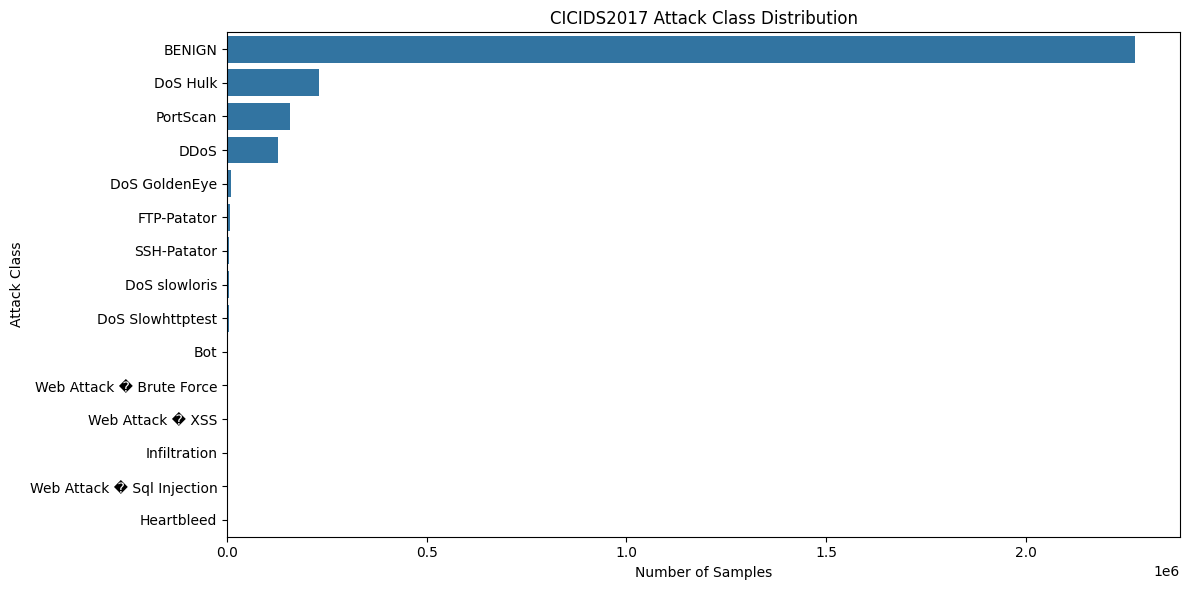


DATA TYPES
int64      54
float64    24
object      1
Name: count, dtype: int64

MISSING VALUES
Flow Bytes/s    1358
dtype: int64

DUPLICATE ROWS
Number of duplicate rows: 308381

STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
Destination Port,2830743.0,8.071483e+03,1.828363e+04,0.0,53.0,80.0,443.0,65535.0
Flow Duration,2830743.0,1.478566e+07,3.365374e+07,-13.0,155.0,31316.0,3204828.5,119999998.0
Total Fwd Packets,2830743.0,9.361160e+00,7.496728e+02,1.0,2.0,2.0,5.0,219759.0
Total Backward Packets,2830743.0,1.039377e+01,9.973883e+02,0.0,1.0,2.0,4.0,291922.0
Total Length of Fwd Packets,2830743.0,5.493024e+02,9.993589e+03,0.0,12.0,62.0,187.0,12900000.0
...,...,...,...,...,...,...,...,...
Active Min,2830743.0,5.829582e+04,5.770923e+05,0.0,0.0,0.0,0.0,110000000.0
Idle Mean,2830743.0,8.316037e+06,2.363008e+07,0.0,0.0,0.0,0.0,120000000.0
Idle Std,2830743.0,5.038439e+05,4.602984e+06,0.0,0.0,0.0,0.0,76900000.0
Idle Max,2830743.0,8.695752e+06,2.436689e+07,0.0,0.0,0.0,0.0,120000000.0


In [4]:
# ============================================================
# 03. DATASET EXPLORATION
# ============================================================

print("Dataset Shape:", data.shape)

print("\n" + "=" * 60)
print("FIRST 5 ROWS")
print("=" * 60)

display(data.head())

# Dataset information

print("\n" + "=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

data.info()

# Check unique attack labels

print("\n" + "=" * 60)
print("UNIQUE LABELS")
print("=" * 60)

print(data[" Label"].unique())

# Count samples for each class

print("\n" + "=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)

label_counts = data[" Label"].value_counts()

print(label_counts)


# Calculate class percentages

label_percentage = (
    data[" Label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\n" + "=" * 60)
print("CLASS DISTRIBUTION (%)")
print("=" * 60)

print(label_percentage)


# Plot class distribution

plt.figure(figsize=(12, 6))

sns.countplot(
    y=data[" Label"],
    order=data[" Label"].value_counts().index
)

plt.title("CICIDS2017 Attack Class Distribution")
plt.xlabel("Number of Samples")
plt.ylabel("Attack Class")

plt.tight_layout()
plt.show()

# Count columns by data type

print("\n" + "=" * 60)
print("DATA TYPES")
print("=" * 60)

print(data.dtypes.value_counts())


# Check missing values

missing_values = data.isnull().sum()

missing_values = missing_values[missing_values > 0]

print("\n" + "=" * 60)
print("MISSING VALUES")
print("=" * 60)

if len(missing_values) == 0:
    print("No missing values found.")
else:
    print(missing_values.sort_values(ascending=False))


# Check duplicate rows

duplicate_count = data.duplicated().sum()

print("\n" + "=" * 60)
print("DUPLICATE ROWS")
print("=" * 60)

print("Number of duplicate rows:", duplicate_count)


# Basic statistical summary

print("\n" + "=" * 60)
print("STATISTICAL SUMMARY")
print("=" * 60)

display(data.describe().T)

In [5]:
# ============================================================
# 04. DATA CLEANING
# ============================================================

# Remove leading and trailing spaces from column names

data.columns = data.columns.str.strip()

print("Column names cleaned successfully.")

print("\nFirst 10 column names:")
print(data.columns[:10].tolist())

print("\nLabel column exists:", "Label" in data.columns)

# Replace infinite values with NaN

data.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Infinite values replaced with NaN.")

# Count missing values after handling infinity

missing = data.isnull().sum()
missing = missing[missing > 0]

print("\nMissing values:")
print(missing)

# Check negative values in numerical columns

numeric_columns = data.select_dtypes(include=[np.number]).columns

negative_counts = (data[numeric_columns] < 0).sum()

negative_counts = negative_counts[negative_counts > 0]

print("\nColumns containing negative values:")
print(negative_counts)

# Remove rows containing missing values

before_missing = len(data)

data.dropna(inplace=True)

after_missing = len(data)

print("Rows before removing missing values:", before_missing)
print("Rows after removing missing values:", after_missing)
print("Rows removed:", before_missing - after_missing)


# Remove duplicate rows

before_duplicates = len(data)

data.drop_duplicates(inplace=True)

after_duplicates = len(data)

print("Rows before removing duplicates:", before_duplicates)
print("Rows after removing duplicates:", after_duplicates)
print("Duplicate rows removed:", before_duplicates - after_duplicates)

# Check final dataset shape

print("\n" + "=" * 60)
print("DATASET AFTER CLEANING")
print("=" * 60)

print("Rows:", data.shape[0])
print("Columns:", data.shape[1])


# Check for remaining missing and infinite values

print("\nRemaining missing values:", data.isnull().sum().sum())

print(
    "Remaining infinite values:",
    np.isinf(data.select_dtypes(include=[np.number])).sum().sum()
)

# Verify duplicate removal

print("Remaining duplicate rows:", data.duplicated().sum())


# ============================================================
# 04.8 HANDLE INVALID NEGATIVE VALUES
# ============================================================

# Select numerical feature columns only
numeric_features = data.select_dtypes(include=[np.number]).columns

# Count negative values before correction
negative_before = (data[numeric_features] < 0).sum().sum()

print("Total negative values before correction:", negative_before)

# Replace negative numerical values with 0
data[numeric_features] = data[numeric_features].clip(lower=0)

# Count negative values after correction
negative_after = (data[numeric_features] < 0).sum().sum()

print("Total negative values after correction:", negative_after)

# Final cleaning verification

print("\n" + "=" * 60)
print("FINAL DATA CLEANING CHECK")
print("=" * 60)

print("Dataset shape:", data.shape)
print("Missing values:", data.isnull().sum().sum())
print("Infinite values:",
      np.isinf(data.select_dtypes(include=[np.number])).sum().sum())
print("Duplicate rows:", data.duplicated().sum())
print("Negative numerical values:",
      (data[numeric_features] < 0).sum().sum())

Column names cleaned successfully.

First 10 column names:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std']

Label column exists: True
Infinite values replaced with NaN.

Missing values:
Flow Bytes/s      2867
Flow Packets/s    2867
dtype: int64

Columns containing negative values:
Flow Duration                  115
Flow Bytes/s                    85
Flow Packets/s                 115
Flow IAT Mean                  115
Flow IAT Max                   115
Flow IAT Min                  2891
Fwd IAT Min                     17
Fwd Header Length               35
Bwd Header Length               22
Fwd Header Length.1             35
Init_Win_bytes_forward     1001189
Init_Win_bytes_backward    1441552
min_seg_size_forward            35
dtype: int64
Rows before removing missing values: 2830743
Rows 

Original labels after cleaning:

Label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

Binary label created successfully.

Label mapping:
Label
BENIGN                        0
Bot                           1
DDoS                          1
DoS GoldenEye                 1
DoS Hulk                      1
DoS Slowhttptest              1
DoS slowloris                 1
FTP-Patator                   1
Heartbleed                    1
Infiltration       

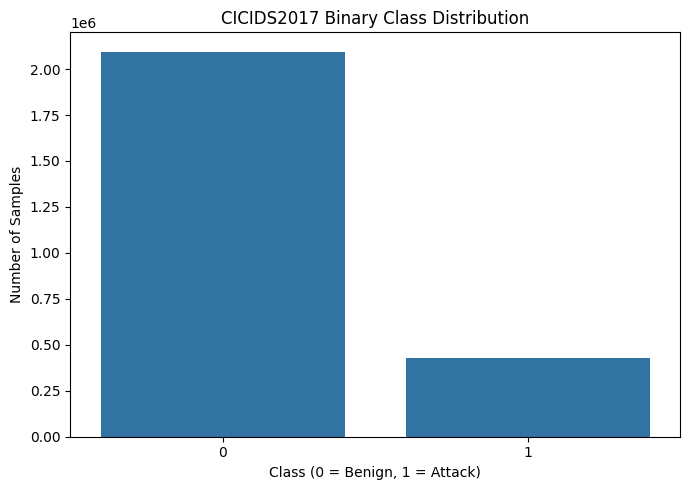

In [6]:
# ============================================================
# 05. LABEL PROCESSING
# ============================================================

print("Original labels after cleaning:\n")

print(data["Label"].value_counts())

# Create binary intrusion-detection label
# BENIGN = 0
# ATTACK = 1

data["Binary_Label"] = (data["Label"] != "BENIGN").astype(np.int8)

print("\nBinary label created successfully.")

# Verify label mapping

print("\nLabel mapping:")
print(
    data.groupby("Label")["Binary_Label"]
    .first()
    .sort_values()
)

# Binary class distribution

binary_counts = data["Binary_Label"].value_counts().sort_index()

print("\n" + "=" * 60)
print("BINARY CLASS DISTRIBUTION")
print("=" * 60)

print("0 = BENIGN")
print("1 = ATTACK\n")

print(binary_counts)

binary_percentage = (
    data["Binary_Label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\n" + "=" * 60)
print("BINARY CLASS DISTRIBUTION (%)")
print("=" * 60)

print(binary_percentage)

plt.figure(figsize=(7, 5))

sns.countplot(
    x=data["Binary_Label"]
)

plt.title("CICIDS2017 Binary Class Distribution")
plt.xlabel("Class (0 = Benign, 1 = Attack)")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# 06. FEATURE PREPROCESSING
# ============================================================

# Separate input features and target

X = data.drop(columns=["Label", "Binary_Label"])
y = data["Binary_Label"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumber of features:", X.shape[1])
print("Target classes:")
print(y.value_counts().sort_index())

# Check feature data types

print("\nFeature data types:")
print(X.dtypes.value_counts())

# Verify feature matrix

print("\nMissing values:", X.isnull().sum().sum())

print(
    "Infinite values:",
    np.isinf(X.to_numpy()).sum()
)

# Check for constant features

constant_features = [
    column for column in X.columns
    if X[column].nunique() <= 1
]

print("Number of constant features:", len(constant_features))

if len(constant_features) > 0:
    print("\nConstant features:")
    print(constant_features)
else:
    print("No constant features found.")


# Remove constant features

if len(constant_features) > 0:
    X = X.drop(columns=constant_features)

print("\nFeature matrix after removing constant features:")
print(X.shape)

# Convert feature values to float32

X = X.astype(np.float32)

print("Feature data type:", X.dtypes.value_counts())


# Check feature ranges

feature_ranges = pd.DataFrame({
    "Minimum": X.min(),
    "Maximum": X.max(),
    "Mean": X.mean()
})

display(feature_ranges)

Feature matrix shape: (2520798, 78)
Target shape: (2520798,)

Number of features: 78
Target classes:
Binary_Label
0    2095057
1     425741
Name: count, dtype: int64

Feature data types:
int64      54
float64    24
Name: count, dtype: int64

Missing values: 0
Infinite values: 0
Number of constant features: 8

Constant features:
['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Feature matrix after removing constant features:
(2520798, 70)
Feature data type: float32    70
Name: count, dtype: int64


,Minimum,Maximum,Mean
Destination Port,0.0,65535.0,8.690591e+03
Flow Duration,0.0,120000000.0,1.659161e+07
Total Fwd Packets,1.0,219759.0,1.028174e+01
Total Backward Packets,0.0,291922.0,1.157281e+01
Total Length of Fwd Packets,0.0,12900000.0,6.119478e+02
...,...,...,...
Active Min,0.0,110000000.0,6.546357e+04
Idle Mean,0.0,120000000.0,9.337366e+06
Idle Std,0.0,76900000.0,5.657941e+05
Idle Max,0.0,120000000.0,9.763771e+06


In [8]:
# ============================================================
# 07. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).sort_index())


# Create and fit scaler using training data only

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")


# Convert scaled arrays to float32

X_train_scaled = X_train_scaled.astype(np.float32)
X_test_scaled = X_test_scaled.astype(np.float32)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nTraining data type:", X_train_scaled.dtype)
print("Testing data type:", X_test_scaled.dtype)


# Verify standardization

print("Mean of first 5 features:")
print(X_train_scaled[:, :5].mean(axis=0))

print("\nStandard deviation of first 5 features:")
print(X_train_scaled[:, :5].std(axis=0))




Training samples: 2016638
Testing samples: 504160

Training class distribution:
Binary_Label
0    0.831109
1    0.168891
Name: proportion, dtype: float64

Testing class distribution:
Binary_Label
0    0.831109
1    0.168891
Name: proportion, dtype: float64
Feature scaling completed.
Training data shape: (2016638, 70)
Testing data shape: (504160, 70)

Training data type: float32
Testing data type: float32
Mean of first 5 features:
[-1.9442938e-08  7.7357489e-09 -3.8210568e-10  3.8683473e-10
 -4.4263729e-10]

Standard deviation of first 5 features:
[0.99999976 1.0000001  1.         0.99999976 1.        ]


Number of clients: 5
Federated rounds: 10
Local epochs: 2
Batch size: 64
Malicious clients: 1
IID client partition created.

Client 1: 403328 samples | Benign: 83.13% | Attack: 16.87%
Client 2: 403328 samples | Benign: 83.12% | Attack: 16.88%
Client 3: 403328 samples | Benign: 83.00% | Attack: 17.00%
Client 4: 403327 samples | Benign: 83.13% | Attack: 16.87%
Client 5: 403327 samples | Benign: 83.17% | Attack: 16.83%


,Client,Benign (%),Attack (%)
0,Client 1,83.129116,16.870884
1,Client 2,83.119694,16.880306
2,Client 3,82.998453,17.001547
3,Client 4,83.132545,16.867455
4,Client 5,83.174447,16.825553


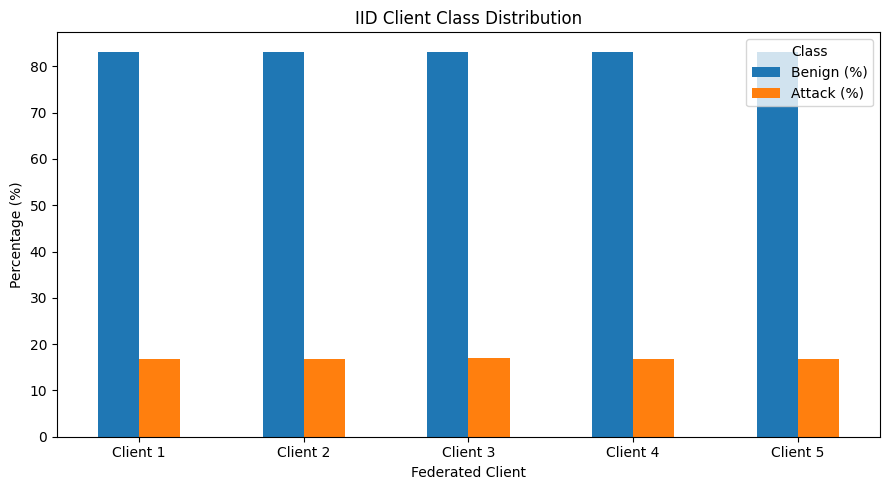

Non-IID Dirichlet alpha: 0.5
Class 0 proportions:
[0.013 0.118 0.838 0.03  0.   ]

Class 1 proportions:
[0.116 0.142 0.403 0.015 0.324]
Non-IID client partition created successfully.


,Client,Samples,Benign (%),Attack (%)
0,Client 1,61888,36.381851,63.618149
1,Client 2,245573,80.295879,19.704121
2,Client 3,1542212,91.103882,8.896118
3,Client 4,55793,90.744359,9.255641
4,Client 5,111172,0.629655,99.370345


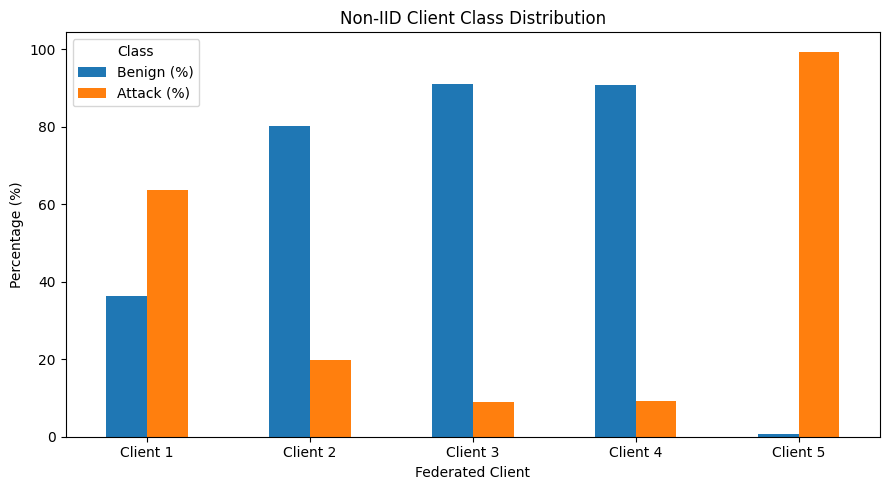

Total training samples: 2016638
IID assigned samples: 2016638
Non-IID assigned samples: 2016638

IID partition correct: True
Non-IID partition correct: True


In [9]:
# ============================================================
# 08. CREATE CLIENT PARTITIONS
# ============================================================

# Federated learning parameters

NUM_CLIENTS = 5
NUM_ROUNDS = 10
LOCAL_EPOCHS = 2
BATCH_SIZE = 64

# Number of malicious clients for poisoning experiment
NUM_MALICIOUS_CLIENTS = 1

print("Number of clients:", NUM_CLIENTS)
print("Federated rounds:", NUM_ROUNDS)
print("Local epochs:", LOCAL_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Malicious clients:", NUM_MALICIOUS_CLIENTS)


# Create IID client partitions

num_train_samples = len(X_train_scaled)

all_indices = np.arange(num_train_samples)

# Shuffle indices
np.random.seed(SEED)
np.random.shuffle(all_indices)

# Split into equal-sized client datasets
iid_client_indices = np.array_split(all_indices, NUM_CLIENTS)

print("IID client partition created.\n")

for i, indices in enumerate(iid_client_indices):
    client_labels = y_train.iloc[indices]

    print(
        f"Client {i + 1}: "
        f"{len(indices)} samples | "
        f"Benign: {(client_labels == 0).mean() * 100:.2f}% | "
        f"Attack: {(client_labels == 1).mean() * 100:.2f}%"
    )


# Calculate class percentages for IID clients

iid_distribution = []

for i, indices in enumerate(iid_client_indices):
    labels = y_train.iloc[indices]

    benign_percentage = (labels == 0).mean() * 100
    attack_percentage = (labels == 1).mean() * 100

    iid_distribution.append({
        "Client": f"Client {i + 1}",
        "Benign (%)": benign_percentage,
        "Attack (%)": attack_percentage
    })

iid_distribution_df = pd.DataFrame(iid_distribution)

display(iid_distribution_df)


# Plot IID client distributions

iid_distribution_df.set_index("Client").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("IID Client Class Distribution")
plt.xlabel("Federated Client")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Class")

plt.tight_layout()
plt.show()


# ============================================================
# NON-IID CLIENT PARTITION
# ============================================================

NON_IID_ALPHA = 0.5

print("Non-IID Dirichlet alpha:", NON_IID_ALPHA)


# Separate training indices by class

class_0_indices = np.where(y_train.to_numpy() == 0)[0]
class_1_indices = np.where(y_train.to_numpy() == 1)[0]

np.random.seed(SEED)

np.random.shuffle(class_0_indices)
np.random.shuffle(class_1_indices)

# Generate Dirichlet proportions for each class
class_0_proportions = np.random.dirichlet(
    [NON_IID_ALPHA] * NUM_CLIENTS
)

class_1_proportions = np.random.dirichlet(
    [NON_IID_ALPHA] * NUM_CLIENTS
)

print("Class 0 proportions:")
print(np.round(class_0_proportions, 3))

print("\nClass 1 proportions:")
print(np.round(class_1_proportions, 3))


# Assign class-specific samples to clients

non_iid_client_indices = [
    [] for _ in range(NUM_CLIENTS)
]

# Allocate benign samples
class_0_splits = (
    class_0_proportions * len(class_0_indices)
).astype(int)

# Correct rounding difference
class_0_splits[-1] = (
    len(class_0_indices) - class_0_splits[:-1].sum()
)

start = 0

for client_id, count in enumerate(class_0_splits):
    end = start + count

    non_iid_client_indices[client_id].extend(
        class_0_indices[start:end]
    )

    start = end


# Allocate attack samples
class_1_splits = (
    class_1_proportions * len(class_1_indices)
).astype(int)

# Correct rounding difference
class_1_splits[-1] = (
    len(class_1_indices) - class_1_splits[:-1].sum()
)

start = 0

for client_id, count in enumerate(class_1_splits):
    end = start + count

    non_iid_client_indices[client_id].extend(
        class_1_indices[start:end]
    )

    start = end


# Shuffle each client's final indices

for client_id in range(NUM_CLIENTS):

    non_iid_client_indices[client_id] = np.array(
        non_iid_client_indices[client_id],
        dtype=np.int32
    )

    np.random.shuffle(
        non_iid_client_indices[client_id]
    )

print("Non-IID client partition created successfully.")



# Display Non-IID client distributions

non_iid_distribution = []

for i, indices in enumerate(non_iid_client_indices):

    labels = y_train.iloc[indices]

    benign_percentage = (labels == 0).mean() * 100
    attack_percentage = (labels == 1).mean() * 100

    non_iid_distribution.append({
        "Client": f"Client {i + 1}",
        "Samples": len(indices),
        "Benign (%)": benign_percentage,
        "Attack (%)": attack_percentage
    })

non_iid_distribution_df = pd.DataFrame(
    non_iid_distribution
)

display(non_iid_distribution_df)


# Plot Non-IID client distributions

non_iid_distribution_df.set_index(
    "Client"
)[["Benign (%)", "Attack (%)"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Non-IID Client Class Distribution")
plt.xlabel("Federated Client")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Class")

plt.tight_layout()
plt.show()



# Verify all training samples are assigned

iid_total = sum(
    len(indices) for indices in iid_client_indices
)

non_iid_total = sum(
    len(indices) for indices in non_iid_client_indices
)

print("Total training samples:", len(X_train_scaled))

print("IID assigned samples:", iid_total)
print("Non-IID assigned samples:", non_iid_total)

print("\nIID partition correct:", iid_total == len(X_train_scaled))
print("Non-IID partition correct:", non_iid_total == len(X_train_scaled))





In [10]:
# ============================================================
# 09. BUILD LOCAL NEURAL NETWORK
# ============================================================

INPUT_DIM = X_train_scaled.shape[1]

print("Number of input features:", INPUT_DIM)


def create_model(input_dim=INPUT_DIM):
    """
    Create the local neural network used by every federated client.
    """

    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),

        layers.Dense(64, activation="relu"),

        layers.Dropout(0.2),

        layers.Dense(32, activation="relu"),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Create a model instance

model = create_model()

model.summary()


# Test model prediction on a small sample

sample_data = X_train_scaled[:5]

sample_predictions = model.predict(
    sample_data,
    verbose=0
)

print("Input shape:", sample_data.shape)
print("Output shape:", sample_predictions.shape)

print("\nSample predictions:")
print(sample_predictions.flatten())


def predictions_to_classes(predictions, threshold=0.5):
    """
    Convert sigmoid probabilities to binary class predictions.
    """

    return (predictions.ravel() >= threshold).astype(np.int8)


# Test prediction conversion

test_predictions = np.array([
    [0.12],
    [0.45],
    [0.51],
    [0.87]
])

print(predictions_to_classes(test_predictions))



def get_model_weights(model):
    """
    Return model weights as a list of NumPy arrays.
    """
    
    return [
        weight.copy()
        for weight in model.get_weights()
    ]


def set_model_weights(model, weights):
    """
    Set model weights from a list of NumPy arrays.
    """
    
    model.set_weights(weights)


# Test weight extraction

initial_weights = get_model_weights(model)

print("Number of weight arrays:", len(initial_weights))

for i, weight in enumerate(initial_weights):
    print(
        f"Weight {i + 1}: "
        f"shape = {weight.shape}"
    )


Number of input features: 70


I0000 00:00:1789233089.672449      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789233089.675465      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,657 (26.00 KB)

 Trainable params: 6,657 (26.00 KB)

 Non-trainable params: 0 (0.00 B)

Input shape: (5, 70)
Output shape: (5, 1)

Sample predictions:
[0.6444867  0.5378828  0.5754255  0.52800137 0.62616   ]
[0 0 1 1]
Number of weight arrays: 6
Weight 1: shape = (70, 64)
Weight 2: shape = (64,)
Weight 3: shape = (64, 32)
Weight 4: shape = (32,)
Weight 5: shape = (32, 1)
Weight 6: shape = (1,)


I0000 00:00:1789233091.462066     176 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Centralized model created.
Epoch 1/5
1773/1773 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9638 - loss: 0.0843 - val_accuracy: 0.9760 - val_loss: 0.0538
Epoch 2/5
1773/1773 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9773 - loss: 0.0505 - val_accuracy: 0.9829 - val_loss: 0.0415
Epoch 3/5
1773/1773 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9815 - loss: 0.0418 - val_accuracy: 0.9843 - val_loss: 0.0353
Epoch 4/5
1773/1773 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9835 - loss: 0.0373 - val_accuracy: 0.9863 - val_loss: 0.0320
Epoch 5/5
1773/1773 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9846 - loss: 0.0348 - val_accuracy: 0.9861 - val_loss: 0.0319
493/493 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9856 - loss: 0.0327

Centralized Test Loss: 0.03274298086762428
Centralized Test Accuracy: 0.9855542182922363
493/493 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Prediction shape: (504160,)
Probability range: 0.0 to 1.0

CENTRALIZED BASELINE RESULTS
Accuracy: 0.9856
Precision: 0.9600

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Centralized,0.985554,0.959983,0.954244,0.957105,0.998819


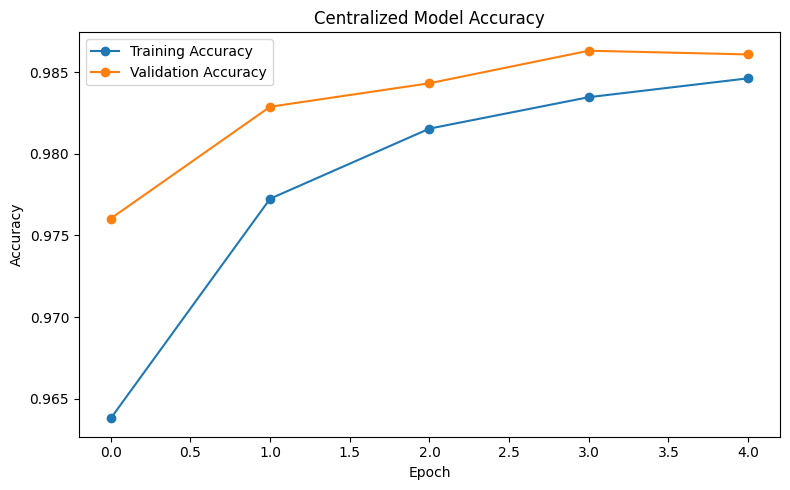

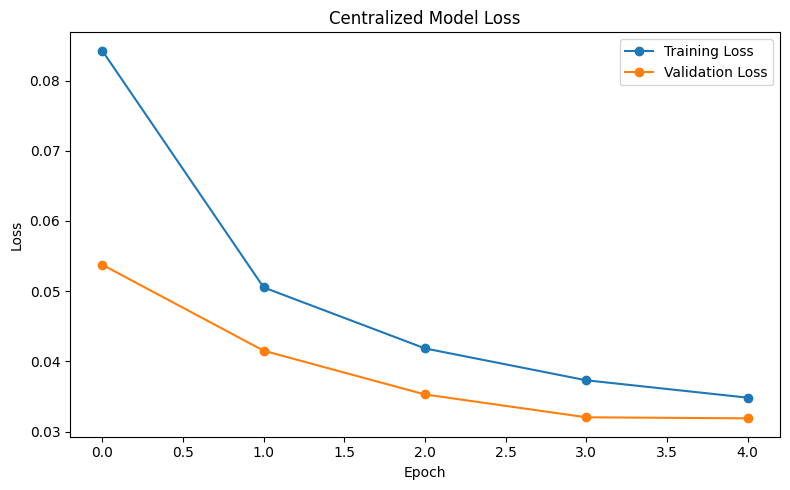

In [11]:
# ============================================================
# 10. CENTRALIZED BASELINE
# ============================================================

centralized_model = create_model()

print("Centralized model created.")


# Train centralized model

centralized_history = centralized_model.fit(
    X_train_scaled,
    y_train.to_numpy(),
    validation_split=0.1,
    epochs=5,
    batch_size=1024,
    verbose=1,
    shuffle=True
)


# Evaluate centralized model on the unseen test set

centralized_test_loss, centralized_test_accuracy = (
    centralized_model.evaluate(
        X_test_scaled,
        y_test.to_numpy(),
        batch_size=1024,
        verbose=1
    )
)

print("\nCentralized Test Loss:", centralized_test_loss)
print("Centralized Test Accuracy:", centralized_test_accuracy)


# Generate probability predictions

centralized_probabilities = centralized_model.predict(
    X_test_scaled,
    batch_size=1024,
    verbose=1
).ravel()

# Convert probabilities to binary predictions

centralized_predictions = (
    centralized_probabilities >= 0.5
).astype(np.int8)

print("Prediction shape:", centralized_predictions.shape)
print("Probability range:",
      centralized_probabilities.min(),
      "to",
      centralized_probabilities.max())



# Evaluation function

def evaluate_model_predictions(y_true, y_pred, y_prob):
    """
    Calculate classification metrics.
    """

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "F1-Score": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true,
            y_prob
        )
    }

    return metrics


# Evaluate centralized baseline

centralized_metrics = evaluate_model_predictions(
    y_test.to_numpy(),
    centralized_predictions,
    centralized_probabilities
)

print("\n" + "=" * 60)
print("CENTRALIZED BASELINE RESULTS")
print("=" * 60)

for metric, value in centralized_metrics.items():
    print(f"{metric}: {value:.4f}")


# Detailed classification report

print(
    classification_report(
        y_test.to_numpy(),
        centralized_predictions,
        target_names=["Benign", "Attack"],
        digits=4
    )
)


# Store centralized results

results = {
    "Centralized": centralized_metrics
}

results_df = pd.DataFrame(results).T

display(results_df)



# Plot centralized training accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    centralized_history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    centralized_history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Centralized Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()



# Plot centralized training loss

plt.figure(figsize=(8, 5))

plt.plot(
    centralized_history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    centralized_history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Centralized Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Global model initialized.
Number of weight arrays: 6
Starting IID Federated Learning...

Federated Round 1/10
  Training Client 1 (403,328 samples)...
  Training Client 2 (403,328 samples)...
  Training Client 3 (403,328 samples)...
  Training Client 4 (403,327 samples)...
  Training Client 5 (403,327 samples)...
  Accuracy : 0.9767
  Precision: 0.9362
  Recall   : 0.9252
  F1-Score : 0.9307
  ROC-AUC  : 0.9970

Federated Round 2/10
  Training Client 1 (403,328 samples)...
  Training Client 2 (403,328 samples)...
  Training Client 3 (403,328 samples)...
  Training Client 4 (403,327 samples)...
  Training Client 5 (403,327 samples)...
  Accuracy : 0.9824
  Precision: 0.9629
  Recall   : 0.9320
  F1-Score : 0.9472
  ROC-AUC  : 0.9985

Federated Round 3/10
  Training Client 1 (403,328 samples)...
  Training Client 2 (403,328 samples)...
  Training Client 3 (403,328 samples)...
  Training Client 4 (403,327 samples)...
  Training Client 5 (403,327 samples)...
  Accuracy : 0.9844
  Precision

,Round,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,1,0.976722,0.936177,0.925248,0.930680,0.997035
1,2,0.982448,0.962873,0.932012,0.947191,0.998450
2,3,0.984360,0.969074,0.937309,0.952927,0.998715
3,4,0.983888,0.963074,0.940668,0.951739,0.998746
4,5,0.985064,0.966085,0.944732,0.955289,0.998907
5,6,0.985239,0.979430,0.932177,0.955219,0.998909
6,7,0.987117,0.972714,0.950381,0.961418,0.998950
7,8,0.987079,0.984952,0.937826,0.960811,0.999118
8,9,0.986504,0.983259,0.936029,0.959063,0.999171
9,10,0.986653,0.984158,0.936041,0.959496,0.999306


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Centralized,0.985554,0.959983,0.954244,0.957105,0.998819
FedAvg-IID,0.986653,0.984158,0.936041,0.959496,0.999306


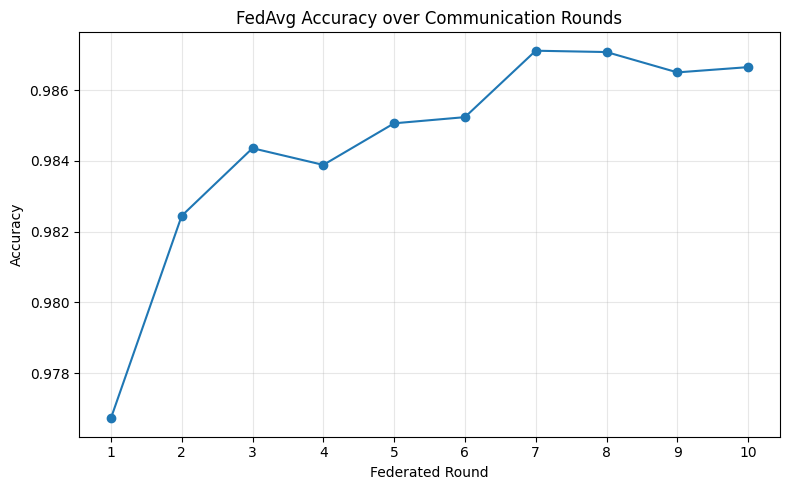

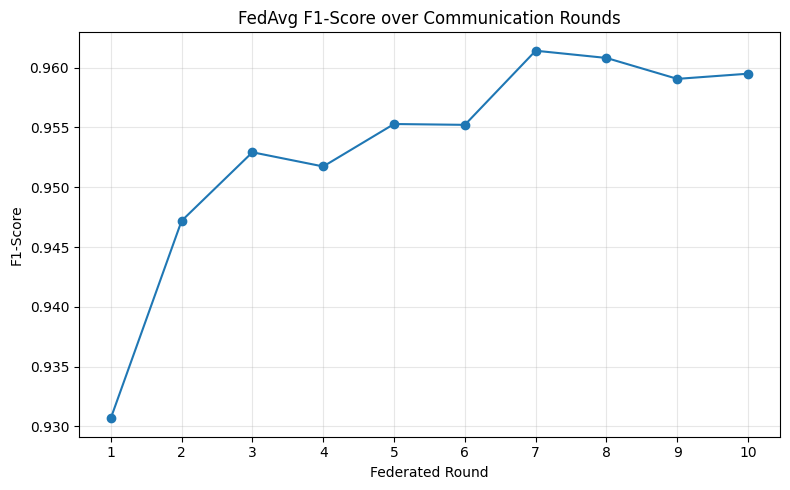

In [12]:
# ============================================================
# 11. FEDERATED LEARNING - FEDAVG
# ============================================================

def train_client(
    global_weights,
    client_indices,
    epochs=LOCAL_EPOCHS,
    batch_size=BATCH_SIZE
):
    """
    Train one client using the current global model.

    Returns:
        local_weights: updated model weights
        num_samples: number of local training samples
    """

    # Create a fresh copy of the model
    local_model = create_model()

    # Start from global model
    set_model_weights(local_model, global_weights)

    # Get client's local data
    X_client = X_train_scaled[client_indices]
    y_client = y_train.to_numpy()[client_indices]

    # Train locally
    local_model.fit(
        X_client,
        y_client,
        epochs=epochs,
        batch_size=batch_size,
        verbose=0,
        shuffle=True
    )

    # Extract updated weights
    local_weights = get_model_weights(local_model)

    num_samples = len(client_indices)

    return local_weights, num_samples



def fedavg_aggregate(client_weights, client_sizes):
    """
    Perform weighted Federated Averaging (FedAvg).
    """

    total_samples = np.sum(client_sizes)

    aggregated_weights = []

    for layer_weights in zip(*client_weights):

        weighted_layer = np.zeros_like(
            layer_weights[0],
            dtype=np.float32
        )

        for weights, size in zip(
            layer_weights,
            client_sizes
        ):

            contribution = size / total_samples

            weighted_layer += (
                contribution * weights
            )

        aggregated_weights.append(weighted_layer)

    return aggregated_weights



# Create the initial global model

global_model = create_model()

global_weights = get_model_weights(global_model)

print("Global model initialized.")
print("Number of weight arrays:", len(global_weights))



def evaluate_global_model(
    model,
    X_test,
    y_test
):
    """
    Evaluate global model on the common test set.
    """

    probabilities = model.predict(
        X_test,
        batch_size=1024,
        verbose=0
    ).ravel()

    predictions = (
        probabilities >= 0.5
    ).astype(np.int8)

    metrics = evaluate_model_predictions(
        y_test,
        predictions,
        probabilities
    )

    return metrics



# ============================================================
# FEDAVG TRAINING - IID CLIENTS
# ============================================================

fedavg_iid_history = []

# Reset global model
global_model = create_model()
global_weights = get_model_weights(global_model)

print("Starting IID Federated Learning...")
print("=" * 60)

for round_number in range(1, NUM_ROUNDS + 1):

    print(f"\nFederated Round {round_number}/{NUM_ROUNDS}")

    client_weights = []
    client_sizes = []

    # --------------------------------------------------------
    # Local client training
    # --------------------------------------------------------

    for client_id, client_indices in enumerate(
        iid_client_indices
    ):

        print(
            f"  Training Client {client_id + 1} "
            f"({len(client_indices):,} samples)..."
        )

        local_weights, num_samples = train_client(
            global_weights,
            client_indices
        )

        client_weights.append(local_weights)
        client_sizes.append(num_samples)

    # --------------------------------------------------------
    # FedAvg aggregation
    # --------------------------------------------------------

    global_weights = fedavg_aggregate(
        client_weights,
        client_sizes
    )

    # Update global model
    set_model_weights(
        global_model,
        global_weights
    )

    # --------------------------------------------------------
    # Evaluate global model
    # --------------------------------------------------------

    round_metrics = evaluate_global_model(
        global_model,
        X_test_scaled,
        y_test.to_numpy()
    )

    round_metrics["Round"] = round_number

    fedavg_iid_history.append(round_metrics)

    print(
        f"  Accuracy : {round_metrics['Accuracy']:.4f}"
    )

    print(
        f"  Precision: {round_metrics['Precision']:.4f}"
    )

    print(
        f"  Recall   : {round_metrics['Recall']:.4f}"
    )

    print(
        f"  F1-Score : {round_metrics['F1-Score']:.4f}"
    )

    print(
        f"  ROC-AUC  : {round_metrics['ROC-AUC']:.4f}"
    )




# Convert federated history to DataFrame

fedavg_iid_history_df = pd.DataFrame(
    fedavg_iid_history
)

fedavg_iid_history_df = fedavg_iid_history_df[
    [
        "Round",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
]

display(fedavg_iid_history_df)




# Store final IID FedAvg result

fedavg_iid_metrics = (
    fedavg_iid_history_df
    .iloc[-1]
    .drop("Round")
    .to_dict()
)

results["FedAvg-IID"] = fedavg_iid_metrics

results_df = pd.DataFrame(results).T

display(results_df)




# Plot FedAvg accuracy over communication rounds

plt.figure(figsize=(8, 5))

plt.plot(
    fedavg_iid_history_df["Round"],
    fedavg_iid_history_df["Accuracy"],
    marker="o"
)

plt.title("FedAvg Accuracy over Communication Rounds")
plt.xlabel("Federated Round")
plt.ylabel("Accuracy")

plt.xticks(
    fedavg_iid_history_df["Round"]
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



# Plot FedAvg F1-score over communication rounds

plt.figure(figsize=(8, 5))

plt.plot(
    fedavg_iid_history_df["Round"],
    fedavg_iid_history_df["F1-Score"],
    marker="o"
)

plt.title("FedAvg F1-Score over Communication Rounds")
plt.xlabel("Federated Round")
plt.ylabel("F1-Score")

plt.xticks(
    fedavg_iid_history_df["Round"]
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# 12. IID FEDERATED EXPERIMENT
# ============================================================

print("=" * 70)
print("IID FEDERATED LEARNING - FINAL RESULTS")
print("=" * 70)

final_iid = fedavg_iid_history_df.iloc[-1]

print(f"Accuracy : {final_iid['Accuracy']:.6f}")
print(f"Precision: {final_iid['Precision']:.6f}")
print(f"Recall   : {final_iid['Recall']:.6f}")
print(f"F1-Score : {final_iid['F1-Score']:.6f}")
print(f"ROC-AUC  : {final_iid['ROC-AUC']:.6f}")


# Create centralized vs IID FedAvg comparison

iid_comparison = pd.DataFrame({
    "Model": [
        "Centralized",
        "FedAvg-IID"
    ],
    
    "Accuracy": [
        centralized_metrics["Accuracy"],
        fedavg_iid_metrics["Accuracy"]
    ],
    
    "Precision": [
        centralized_metrics["Precision"],
        fedavg_iid_metrics["Precision"]
    ],
    
    "Recall": [
        centralized_metrics["Recall"],
        fedavg_iid_metrics["Recall"]
    ],
    
    "F1-Score": [
        centralized_metrics["F1-Score"],
        fedavg_iid_metrics["F1-Score"]
    ],
    
    "ROC-AUC": [
        centralized_metrics["ROC-AUC"],
        fedavg_iid_metrics["ROC-AUC"]
    ]
})

display(iid_comparison)



# Calculate FedAvg-IID improvement/difference
# relative to the centralized baseline

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

iid_difference = {}

for metric in metric_names:
    
    difference = (
        fedavg_iid_metrics[metric]
        - centralized_metrics[metric]
    )
    
    iid_difference[metric] = difference

iid_difference_df = pd.DataFrame(
    [iid_difference],
    index=["FedAvg-IID - Centralized"]
)

display(iid_difference_df)



# Save the final IID FedAvg global model

iid_global_weights = get_model_weights(global_model)

print("IID global model weights saved.")
print("Number of weight arrays:", len(iid_global_weights))



# Save IID training history in memory

iid_history = fedavg_iid_history_df.copy()

print("IID training history saved.")




# Prepare IID convergence data

iid_convergence = fedavg_iid_history_df[
    ["Round", "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
].copy()

display(iid_convergence)

IID FEDERATED LEARNING - FINAL RESULTS
Accuracy : 0.986653
Precision: 0.984158
Recall   : 0.936041
F1-Score : 0.959496
ROC-AUC  : 0.999306


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Centralized,0.985554,0.959983,0.954244,0.957105,0.998819
1,FedAvg-IID,0.986653,0.984158,0.936041,0.959496,0.999306


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
FedAvg-IID - Centralized,0.001099,0.024175,-0.018204,0.002391,0.000487


IID global model weights saved.
Number of weight arrays: 6
IID training history saved.


,Round,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,1,0.976722,0.936177,0.925248,0.930680,0.997035
1,2,0.982448,0.962873,0.932012,0.947191,0.998450
2,3,0.984360,0.969074,0.937309,0.952927,0.998715
3,4,0.983888,0.963074,0.940668,0.951739,0.998746
4,5,0.985064,0.966085,0.944732,0.955289,0.998907
5,6,0.985239,0.979430,0.932177,0.955219,0.998909
6,7,0.987117,0.972714,0.950381,0.961418,0.998950
7,8,0.987079,0.984952,0.937826,0.960811,0.999118
8,9,0.986504,0.983259,0.936029,0.959063,0.999171
9,10,0.986653,0.984158,0.936041,0.959496,0.999306


In [14]:
# ============================================================
# 13. NON-IID FEDERATED EXPERIMENT
# ============================================================

# Create a fresh global model

noniid_global_model = create_model()

noniid_global_weights = get_model_weights(
    noniid_global_model
)

print("Fresh Non-IID global model initialized.")
print(
    "Number of weight arrays:",
    len(noniid_global_weights)
)


# Non-IID FedAvg training

fedavg_noniid_history = []

print("Starting Non-IID Federated Learning...")
print("=" * 60)

for round_number in range(1, NUM_ROUNDS + 1):

    print(
        f"\nFederated Round "
        f"{round_number}/{NUM_ROUNDS}"
    )

    client_weights = []
    client_sizes = []

    # --------------------------------------------------------
    # Local client training
    # --------------------------------------------------------

    for client_id, client_indices in enumerate(
        non_iid_client_indices
    ):

        print(
            f"  Training Client {client_id + 1} "
            f"({len(client_indices):,} samples)..."
        )

        local_weights, num_samples = train_client(
            noniid_global_weights,
            client_indices,
            epochs=LOCAL_EPOCHS,
            batch_size=BATCH_SIZE
        )

        client_weights.append(local_weights)
        client_sizes.append(num_samples)

    # --------------------------------------------------------
    # FedAvg aggregation
    # --------------------------------------------------------

    noniid_global_weights = fedavg_aggregate(
        client_weights,
        client_sizes
    )

    # Update global model
    set_model_weights(
        noniid_global_model,
        noniid_global_weights
    )

    # --------------------------------------------------------
    # Evaluate global model
    # --------------------------------------------------------

    round_metrics = evaluate_global_model(
        noniid_global_model,
        X_test_scaled,
        y_test.to_numpy()
    )

    round_metrics["Round"] = round_number

    fedavg_noniid_history.append(
        round_metrics
    )

    print(
        f"  Accuracy : "
        f"{round_metrics['Accuracy']:.4f}"
    )

    print(
        f"  Precision: "
        f"{round_metrics['Precision']:.4f}"
    )

    print(
        f"  Recall   : "
        f"{round_metrics['Recall']:.4f}"
    )

    print(
        f"  F1-Score : "
        f"{round_metrics['F1-Score']:.4f}"
    )

    print(
        f"  ROC-AUC  : "
        f"{round_metrics['ROC-AUC']:.4f}"
    )



# Convert Non-IID history to DataFrame

fedavg_noniid_history_df = pd.DataFrame(
    fedavg_noniid_history
)

fedavg_noniid_history_df = fedavg_noniid_history_df[
    [
        "Round",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
]

display(fedavg_noniid_history_df)


# Store final Non-IID FedAvg result

fedavg_noniid_metrics = (
    fedavg_noniid_history_df
    .iloc[-1]
    .drop("Round")
    .to_dict()
)

results["FedAvg-NonIID"] = fedavg_noniid_metrics

results_df = pd.DataFrame(results).T

display(results_df)


Fresh Non-IID global model initialized.
Number of weight arrays: 6
Starting Non-IID Federated Learning...

Federated Round 1/10
  Training Client 1 (61,888 samples)...
  Training Client 2 (245,573 samples)...
  Training Client 3 (1,542,212 samples)...
  Training Client 4 (55,793 samples)...
  Training Client 5 (111,172 samples)...
  Accuracy : 0.9809
  Precision: 0.9900
  Recall   : 0.8959
  F1-Score : 0.9406
  ROC-AUC  : 0.9982

Federated Round 2/10
  Training Client 1 (61,888 samples)...
  Training Client 2 (245,573 samples)...
  Training Client 3 (1,542,212 samples)...
  Training Client 4 (55,793 samples)...
  Training Client 5 (111,172 samples)...
  Accuracy : 0.9839
  Precision: 0.9760
  Recall   : 0.9276
  F1-Score : 0.9512
  ROC-AUC  : 0.9985

Federated Round 3/10
  Training Client 1 (61,888 samples)...
  Training Client 2 (245,573 samples)...
  Training Client 3 (1,542,212 samples)...
  Training Client 4 (55,793 samples)...
  Training Client 5 (111,172 samples)...
  Accuracy : 

,Round,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,1,0.980881,0.989968,0.895875,0.940574,0.998179
1,2,0.983918,0.975955,0.927632,0.951180,0.998543
2,3,0.985138,0.983946,0.927127,0.954692,0.998721
3,4,0.988494,0.985119,0.946164,0.965249,0.999024
4,5,0.988940,0.981030,0.952941,0.966781,0.999125
5,6,0.993308,0.991809,0.968373,0.979951,0.999512
6,7,0.987919,0.989547,0.938378,0.963284,0.999196
7,8,0.984295,0.982398,0.923557,0.952069,0.998688
8,9,0.984642,0.983485,0.924590,0.953129,0.998740
9,10,0.984820,0.966472,0.942829,0.954504,0.998818


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Centralized,0.985554,0.959983,0.954244,0.957105,0.998819
FedAvg-IID,0.986653,0.984158,0.936041,0.959496,0.999306
FedAvg-NonIID,0.984820,0.966472,0.942829,0.954504,0.998818


In [16]:
# ============================================================
# 14. LABEL-FLIPPING ATTACK
# ============================================================

MALICIOUS_CLIENTS = [0]   # Client 1 is malicious

print("Malicious clients:", [c + 1 for c in MALICIOUS_CLIENTS])
print("Number of malicious clients:", len(MALICIOUS_CLIENTS))
print("Total clients:", NUM_CLIENTS)

malicious_fraction = (
    len(MALICIOUS_CLIENTS) / NUM_CLIENTS
)

print(
    f"Malicious client fraction: "
    f"{malicious_fraction:.1%}"
)


def flip_labels(labels):
    """
    Perform binary label-flipping poisoning.

    Benign (0) -> Attack (1)
    Attack (1) -> Benign (0)
    """

    poisoned_labels = 1 - labels

    return poisoned_labels.astype(np.int8)


# Test label flipping

test_labels = np.array([0, 0, 1, 1, 0, 1])

print("Original labels :", test_labels)
print("Flipped labels  :", flip_labels(test_labels))




# Select Client 1's IID data for verification

malicious_client_indices = iid_client_indices[0]

original_client_labels = (
    y_train.to_numpy()[malicious_client_indices]
)

poisoned_client_labels = flip_labels(
    original_client_labels
)

print("=" * 60)
print("LABEL-FLIPPING VERIFICATION")
print("=" * 60)

print(
    "Original Benign:",
    np.sum(original_client_labels == 0)
)

print(
    "Original Attack:",
    np.sum(original_client_labels == 1)
)

print(
    "Poisoned Benign:",
    np.sum(poisoned_client_labels == 0)
)

print(
    "Poisoned Attack:",
    np.sum(poisoned_client_labels == 1)
)




def train_client_with_label_flipping(
    global_weights,
    client_indices,
    malicious=False,
    epochs=LOCAL_EPOCHS,
    batch_size=BATCH_SIZE
):
    """
    Train a local client.

    If malicious=True, labels are flipped before local training.
    """

    # Create local model
    local_model = create_model()

    # Initialize from global model
    set_model_weights(
        local_model,
        global_weights
    )

    # Obtain local data
    X_client = X_train_scaled[client_indices]

    y_client = y_train.to_numpy()[client_indices]

    # --------------------------------------------------------
    # Apply poisoning attack
    # --------------------------------------------------------

    if malicious:

        y_client = flip_labels(y_client)

    # --------------------------------------------------------
    # Local training
    # --------------------------------------------------------

    local_model.fit(
        X_client,
        y_client,
        epochs=epochs,
        batch_size=batch_size,
        verbose=0,
        shuffle=True
    )

    # Return updated model parameters
    local_weights = get_model_weights(
        local_model
    )

    return local_weights, len(client_indices)




# Test honest client training

test_global_model = create_model()

test_global_weights = get_model_weights(
    test_global_model
)

honest_weights, honest_size = (
    train_client_with_label_flipping(
        test_global_weights,
        iid_client_indices[0],
        malicious=False,
        epochs=1
    )
)

print("Honest client training completed.")
print("Samples:", honest_size)




# Test malicious client training

malicious_weights, malicious_size = (
    train_client_with_label_flipping(
        test_global_weights,
        iid_client_indices[0],
        malicious=True,
        epochs=1
    )
)

print("Malicious client training completed.")
print("Samples:", malicious_size)





Malicious clients: [1]
Number of malicious clients: 1
Total clients: 5
Malicious client fraction: 20.0%
Original labels : [0 0 1 1 0 1]
Flipped labels  : [1 1 0 0 1 0]
LABEL-FLIPPING VERIFICATION
Original Benign: 335283
Original Attack: 68045
Poisoned Benign: 68045
Poisoned Attack: 335283
Honest client training completed.
Samples: 403328
Malicious client training completed.
Samples: 403328


In [17]:
# ============================================================
# 15. FEDAVG UNDER LABEL-FLIPPING POISONING
# ============================================================

poisoned_global_model = create_model()

poisoned_global_weights = get_model_weights(
    poisoned_global_model
)

print("Fresh poisoned-FedAvg global model initialized.")



fedavg_poisoned_history = []

print("Starting FedAvg under label-flipping attack...")
print("=" * 70)

for round_number in range(1, NUM_ROUNDS + 1):

    print(
        f"\nFederated Round "
        f"{round_number}/{NUM_ROUNDS}"
    )

    client_weights = []
    client_sizes = []

    # --------------------------------------------------------
    # Client training
    # --------------------------------------------------------

    for client_id, client_indices in enumerate(
        iid_client_indices
    ):

        is_malicious = (
            client_id in MALICIOUS_CLIENTS
        )

        client_type = (
            "MALICIOUS"
            if is_malicious
            else "HONEST"
        )

        print(
            f"  Client {client_id + 1} "
            f"[{client_type}] "
            f"({len(client_indices):,} samples)..."
        )

        local_weights, num_samples = (
            train_client_with_label_flipping(
                poisoned_global_weights,
                client_indices,
                malicious=is_malicious,
                epochs=LOCAL_EPOCHS,
                batch_size=BATCH_SIZE
            )
        )

        client_weights.append(
            local_weights
        )

        client_sizes.append(
            num_samples
        )

    # --------------------------------------------------------
    # Standard FedAvg aggregation
    # --------------------------------------------------------

    poisoned_global_weights = fedavg_aggregate(
        client_weights,
        client_sizes
    )

    # Update global model
    set_model_weights(
        poisoned_global_model,
        poisoned_global_weights
    )

    # --------------------------------------------------------
    # Evaluate global model
    # --------------------------------------------------------

    round_metrics = evaluate_global_model(
        poisoned_global_model,
        X_test_scaled,
        y_test.to_numpy()
    )

    round_metrics["Round"] = round_number

    fedavg_poisoned_history.append(
        round_metrics
    )

    print(
        f"  Accuracy : "
        f"{round_metrics['Accuracy']:.4f}"
    )

    print(
        f"  Precision: "
        f"{round_metrics['Precision']:.4f}"
    )

    print(
        f"  Recall   : "
        f"{round_metrics['Recall']:.4f}"
    )

    print(
        f"  F1-Score : "
        f"{round_metrics['F1-Score']:.4f}"
    )

    print(
        f"  ROC-AUC  : "
        f"{round_metrics['ROC-AUC']:.4f}"
    )




# Convert poisoning history to DataFrame

fedavg_poisoned_history_df = pd.DataFrame(
    fedavg_poisoned_history
)

fedavg_poisoned_history_df = (
    fedavg_poisoned_history_df[
        [
            "Round",
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score",
            "ROC-AUC"
        ]
    ]
)

display(
    fedavg_poisoned_history_df
)



# Store final poisoned FedAvg result

fedavg_poisoned_metrics = (
    fedavg_poisoned_history_df
    .iloc[-1]
    .drop("Round")
    .to_dict()
)

results["FedAvg-Poisoned"] = (
    fedavg_poisoned_metrics
)

results_df = pd.DataFrame(results).T

display(results_df)

Fresh poisoned-FedAvg global model initialized.
Starting FedAvg under label-flipping attack...

Federated Round 1/10
  Client 1 [MALICIOUS] (403,328 samples)...
  Client 2 [HONEST] (403,328 samples)...
  Client 3 [HONEST] (403,328 samples)...
  Client 4 [HONEST] (403,327 samples)...
  Client 5 [HONEST] (403,327 samples)...
  Accuracy : 0.9761
  Precision: 0.9266
  Recall   : 0.9320
  F1-Score : 0.9293
  ROC-AUC  : 0.9971

Federated Round 2/10
  Client 1 [MALICIOUS] (403,328 samples)...
  Client 2 [HONEST] (403,328 samples)...
  Client 3 [HONEST] (403,328 samples)...
  Client 4 [HONEST] (403,327 samples)...
  Client 5 [HONEST] (403,327 samples)...
  Accuracy : 0.9767
  Precision: 0.9576
  Recall   : 0.9022
  F1-Score : 0.9291
  ROC-AUC  : 0.9969

Federated Round 3/10
  Client 1 [MALICIOUS] (403,328 samples)...
  Client 2 [HONEST] (403,328 samples)...
  Client 3 [HONEST] (403,328 samples)...
  Client 4 [HONEST] (403,327 samples)...
  Client 5 [HONEST] (403,327 samples)...
  Accuracy : 0.

,Round,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,1,0.976057,0.926637,0.932024,0.929323,0.997093
1,2,0.976736,0.957559,0.902241,0.929077,0.996889
2,3,0.977410,0.952193,0.912036,0.931682,0.996881
3,4,0.980619,0.974409,0.909123,0.940635,0.996915
4,5,0.979826,0.974352,0.904355,0.938049,0.997365
5,6,0.980506,0.978174,0.904766,0.940039,0.998137
6,7,0.981797,0.978064,0.912693,0.944248,0.998417
7,8,0.985382,0.953993,0.959729,0.956852,0.998659
8,9,0.985751,0.958536,0.957028,0.957781,0.998749
9,10,0.981014,0.983124,0.903086,0.941407,0.998562


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Centralized,0.985554,0.959983,0.954244,0.957105,0.998819
FedAvg-IID,0.986653,0.984158,0.936041,0.959496,0.999306
FedAvg-NonIID,0.984820,0.966472,0.942829,0.954504,0.998818
FedAvg-Poisoned,0.981014,0.983124,0.903086,0.941407,0.998562


In [18]:
# ============================================================
# 16. MEDIAN AGGREGATION
# ============================================================

def median_aggregate(client_weights):
    """
    Coordinate-wise median aggregation.
    Each parameter is aggregated independently using
    the median across client updates.
    """
    
    aggregated_weights = []

    for layer_weights in zip(*client_weights):
        stacked_weights = np.stack(layer_weights, axis=0)
        median_layer = np.median(stacked_weights, axis=0)
        
        aggregated_weights.append(
            median_layer.astype(np.float32)
        )

    return aggregated_weights


print("Median aggregation function created.")



# ============================================================
# MEDIAN AGGREGATION UNDER LABEL-FLIPPING ATTACK
# ============================================================

median_global_model = create_model()

print("Fresh Median global model initialized.")
print("Starting Median aggregation under label-flipping attack...")
print("=" * 70)

median_history = []

for round_num in range(1, NUM_ROUNDS + 1):

    print(f"\nFederated Round {round_num}/{NUM_ROUNDS}")

    global_weights = get_model_weights(median_global_model)

    client_weights = []
    client_sizes = []

    for client_id, client_indices in enumerate(iid_client_indices):

        is_malicious = client_id in MALICIOUS_CLIENTS

        status = "MALICIOUS" if is_malicious else "HONEST"

        print(
            f"  Client {client_id + 1} "
            f"[{status}] "
            f"({len(client_indices):,} samples)..."
        )

        local_weights, local_size = train_client_with_label_flipping(
            global_weights=global_weights,
            client_indices=client_indices,
            malicious=is_malicious,
            epochs=LOCAL_EPOCHS,
            batch_size=BATCH_SIZE
        )

        client_weights.append(local_weights)
        client_sizes.append(local_size)

    # Median aggregation
    new_global_weights = median_aggregate(client_weights)

    set_model_weights(
        median_global_model,
        new_global_weights
    )

    # Evaluate global model
    round_metrics = evaluate_global_model(
        median_global_model,
        X_test_scaled,
        y_test
    )

    round_metrics["Round"] = round_num
    median_history.append(round_metrics)

    print(f"  Accuracy : {round_metrics['Accuracy']:.4f}")
    print(f"  Precision: {round_metrics['Precision']:.4f}")
    print(f"  Recall   : {round_metrics['Recall']:.4f}")
    print(f"  F1-Score : {round_metrics['F1-Score']:.4f}")
    print(f"  ROC-AUC  : {round_metrics['ROC-AUC']:.4f}")


# Convert history to DataFrame
median_history_df = pd.DataFrame(median_history)

print("\n" + "=" * 70)
print("MEDIAN AGGREGATION RESULTS")
print("=" * 70)

display(median_history_df)




# ============================================================
# FINAL MEDIAN RESULT
# ============================================================

median_metrics = median_history_df.iloc[-1].to_dict()

print("Final Median Aggregation Metrics:")
print("-" * 50)

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]:
    print(f"{metric:10s}: {median_metrics[metric]:.6f}")




results["Median-Poisoned"] = {
    "Accuracy": median_metrics["Accuracy"],
    "Precision": median_metrics["Precision"],
    "Recall": median_metrics["Recall"],
    "F1-Score": median_metrics["F1-Score"],
    "ROC-AUC": median_metrics["ROC-AUC"]
}

print("\nMedian result added to results dictionary.")



Median aggregation function created.
Fresh Median global model initialized.
Starting Median aggregation under label-flipping attack...

Federated Round 1/10
  Client 1 [MALICIOUS] (403,328 samples)...
  Client 2 [HONEST] (403,328 samples)...
  Client 3 [HONEST] (403,328 samples)...
  Client 4 [HONEST] (403,327 samples)...
  Client 5 [HONEST] (403,327 samples)...
  Accuracy : 0.9785
  Precision: 0.9592
  Recall   : 0.9113
  F1-Score : 0.9346
  ROC-AUC  : 0.9974

Federated Round 2/10
  Client 1 [MALICIOUS] (403,328 samples)...
  Client 2 [HONEST] (403,328 samples)...
  Client 3 [HONEST] (403,328 samples)...
  Client 4 [HONEST] (403,327 samples)...
  Client 5 [HONEST] (403,327 samples)...
  Accuracy : 0.9814
  Precision: 0.9605
  Recall   : 0.9279
  F1-Score : 0.9439
  ROC-AUC  : 0.9983

Federated Round 3/10
  Client 1 [MALICIOUS] (403,328 samples)...
  Client 2 [HONEST] (403,328 samples)...
  Client 3 [HONEST] (403,328 samples)...
  Client 4 [HONEST] (403,327 samples)...
  Client 5 [HONE

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Round
0,0.978471,0.959217,0.911272,0.934630,0.997376,1
1,0.981367,0.960455,0.927879,0.943886,0.998349,2
2,0.983454,0.967816,0.933058,0.950119,0.998690,3
3,0.984457,0.971403,0.935512,0.953120,0.998838,4
4,0.985100,0.981852,0.928947,0.954667,0.998859,5
5,0.985340,0.980723,0.931507,0.955482,0.998931,6
6,0.987675,0.981317,0.945013,0.962823,0.999056,7
7,0.983612,0.981019,0.920785,0.949948,0.998737,8
8,0.985804,0.986829,0.928337,0.956690,0.999045,9
9,0.986028,0.985178,0.931284,0.957474,0.999044,10


Final Median Aggregation Metrics:
--------------------------------------------------
Accuracy  : 0.986028
Precision : 0.985178
Recall    : 0.931284
F1-Score  : 0.957474
ROC-AUC   : 0.999044

Median result added to results dictionary.


In [19]:
# ============================================================
# 17. KRUM AGGREGATION
# ============================================================

def flatten_weights(weights):
    """Flatten all model weight arrays into one vector."""
    return np.concatenate([
        weight.ravel() for weight in weights
    ])


def krum_aggregate(client_weights, num_malicious=1):
    """
    Krum aggregation.

    Selects the client update whose distances to the
    closest client updates have the smallest total distance.
    """

    num_clients = len(client_weights)

    # Flatten each client's model weights
    flat_weights = np.array([
        flatten_weights(weights)
        for weights in client_weights
    ])

    # Calculate pairwise squared Euclidean distances
    distances = np.zeros((num_clients, num_clients))

    for i in range(num_clients):
        for j in range(num_clients):
            if i != j:
                difference = flat_weights[i] - flat_weights[j]
                distances[i, j] = np.sum(difference ** 2)

    # Number of closest updates considered
    num_closest = num_clients - num_malicious - 2

    # Calculate Krum score
    krum_scores = []

    for i in range(num_clients):

        other_distances = np.delete(
            distances[i],
            i
        )

        closest_distances = np.sort(other_distances)[
            :num_closest
        ]

        score = np.sum(closest_distances)

        krum_scores.append(score)

    # Select client with smallest Krum score
    selected_client = np.argmin(krum_scores)

    print(
        f"  Krum selected Client {selected_client + 1} "
        f"(score: {krum_scores[selected_client]:.6e})"
    )

    # Return the selected client's complete model weights
    selected_weights = [
        weight.copy()
        for weight in client_weights[selected_client]
    ]

    return selected_weights


# ============================================================
# KRUM FUNCTION VERIFICATION
# ============================================================

print("Krum aggregation function created.")

print(f"Number of clients : {NUM_CLIENTS}")
print(f"Malicious clients : {NUM_MALICIOUS_CLIENTS}")
print(
    f"Closest updates considered: "
    f"{NUM_CLIENTS - NUM_MALICIOUS_CLIENTS - 2}"
)



# ============================================================
# KRUM AGGREGATION UNDER LABEL-FLIPPING ATTACK
# ============================================================

krum_global_model = create_model()

print("Fresh Krum global model initialized.")
print("Starting Krum aggregation under label-flipping attack...")
print("=" * 70)

krum_history = []

for round_num in range(1, NUM_ROUNDS + 1):

    print(f"\nFederated Round {round_num}/{NUM_ROUNDS}")

    global_weights = get_model_weights(krum_global_model)

    client_weights = []
    client_sizes = []

    for client_id, client_indices in enumerate(iid_client_indices):

        is_malicious = client_id in MALICIOUS_CLIENTS

        status = "MALICIOUS" if is_malicious else "HONEST"

        print(
            f"  Client {client_id + 1} "
            f"[{status}] "
            f"({len(client_indices):,} samples)..."
        )

        local_weights, local_size = train_client_with_label_flipping(
            global_weights=global_weights,
            client_indices=client_indices,
            malicious=is_malicious,
            epochs=LOCAL_EPOCHS,
            batch_size=BATCH_SIZE
        )

        client_weights.append(local_weights)
        client_sizes.append(local_size)

    # Krum aggregation
    new_global_weights = krum_aggregate(
        client_weights,
        num_malicious=NUM_MALICIOUS_CLIENTS
    )

    set_model_weights(
        krum_global_model,
        new_global_weights
    )

    # Evaluate global model
    round_metrics = evaluate_global_model(
        krum_global_model,
        X_test_scaled,
        y_test
    )

    round_metrics["Round"] = round_num
    krum_history.append(round_metrics)

    print(f"  Accuracy : {round_metrics['Accuracy']:.4f}")
    print(f"  Precision: {round_metrics['Precision']:.4f}")
    print(f"  Recall   : {round_metrics['Recall']:.4f}")
    print(f"  F1-Score : {round_metrics['F1-Score']:.4f}")
    print(f"  ROC-AUC  : {round_metrics['ROC-AUC']:.4f}")


# Convert history to DataFrame
krum_history_df = pd.DataFrame(krum_history)

print("\n" + "=" * 70)
print("KRUM AGGREGATION RESULTS")
print("=" * 70)

display(krum_history_df)



# ============================================================
# FINAL KRUM RESULT
# ============================================================

krum_metrics = krum_history_df.iloc[-1].to_dict()

print("Final Krum Aggregation Metrics:")
print("-" * 50)

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]:
    print(f"{metric:10s}: {krum_metrics[metric]:.6f}")



# ============================================================
# SAVE KRUM RESULT
# ============================================================

results["Krum-Poisoned"] = {
    "Accuracy": krum_metrics["Accuracy"],
    "Precision": krum_metrics["Precision"],
    "Recall": krum_metrics["Recall"],
    "F1-Score": krum_metrics["F1-Score"],
    "ROC-AUC": krum_metrics["ROC-AUC"]
}

print("\nKrum result added to results dictionary.")

Krum aggregation function created.
Number of clients : 5
Malicious clients : 1
Closest updates considered: 2
Fresh Krum global model initialized.
Starting Krum aggregation under label-flipping attack...

Federated Round 1/10
  Client 1 [MALICIOUS] (403,328 samples)...
  Client 2 [HONEST] (403,328 samples)...
  Client 3 [HONEST] (403,328 samples)...
  Client 4 [HONEST] (403,327 samples)...
  Client 5 [HONEST] (403,327 samples)...
  Krum selected Client 2 (score: 2.064528e+02)
  Accuracy : 0.9797
  Precision: 0.9482
  Recall   : 0.9306
  F1-Score : 0.9393
  ROC-AUC  : 0.9975

Federated Round 2/10
  Client 1 [MALICIOUS] (403,328 samples)...
  Client 2 [HONEST] (403,328 samples)...
  Client 3 [HONEST] (403,328 samples)...
  Client 4 [HONEST] (403,327 samples)...
  Client 5 [HONEST] (403,327 samples)...
  Krum selected Client 2 (score: 6.228433e+01)
  Accuracy : 0.9809
  Precision: 0.9509
  Recall   : 0.9354
  F1-Score : 0.9431
  ROC-AUC  : 0.9981

Federated Round 3/10
  Client 1 [MALICIOUS

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Round
0,0.979687,0.948185,0.930580,0.939300,0.997457,1
1,0.980929,0.950916,0.935360,0.943074,0.998083,2
2,0.981615,0.977689,0.911953,0.943678,0.998450,3
3,0.984763,0.945340,0.965613,0.955369,0.998665,4
4,0.984475,0.974869,0.932106,0.953008,0.998802,5
5,0.984166,0.982191,0.922981,0.951666,0.998805,6
6,0.985346,0.985212,0.927150,0.955300,0.998994,7
7,0.984973,0.988243,0.921995,0.953970,0.999156,8
8,0.986455,0.952444,0.968138,0.960227,0.998901,9
9,0.985526,0.988639,0.924931,0.955725,0.999316,10


Final Krum Aggregation Metrics:
--------------------------------------------------
Accuracy  : 0.985526
Precision : 0.988639
Recall    : 0.924931
F1-Score  : 0.955725
ROC-AUC   : 0.999316

Krum result added to results dictionary.


In [20]:
# ============================================================
# 18. COMPARE ROBUSTNESS
# ============================================================

robustness_results = pd.DataFrame({
    "FedAvg-Poisoned": results["FedAvg-Poisoned"],
    "Median-Poisoned": results["Median-Poisoned"],
    "Krum-Poisoned": results["Krum-Poisoned"]
}).T

print("=" * 80)
print("ROBUST AGGREGATION COMPARISON")
print("=" * 80)

display(robustness_results)


# ============================================================
# IMPROVEMENT OVER POISONED FEDAVG
# ============================================================

baseline = robustness_results.loc["FedAvg-Poisoned"]

improvement = robustness_results.subtract(baseline)

print("=" * 80)
print("IMPROVEMENT / CHANGE RELATIVE TO POISONED FEDAVG")
print("=" * 80)

display(improvement)


# ============================================================
# CLEAN VS POISONED FEDAVG
# ============================================================

clean_vs_poisoned = pd.DataFrame({
    "FedAvg-IID": results["FedAvg-IID"],
    "FedAvg-Poisoned": results["FedAvg-Poisoned"],
    "Median-Poisoned": results["Median-Poisoned"],
    "Krum-Poisoned": results["Krum-Poisoned"]
}).T

print("=" * 80)
print("CLEAN VS POISONED FEDERATED LEARNING")
print("=" * 80)

display(clean_vs_poisoned)





ROBUST AGGREGATION COMPARISON


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
FedAvg-Poisoned,0.981014,0.983124,0.903086,0.941407,0.998562
Median-Poisoned,0.986028,0.985178,0.931284,0.957474,0.999044
Krum-Poisoned,0.985526,0.988639,0.924931,0.955725,0.999316


IMPROVEMENT / CHANGE RELATIVE TO POISONED FEDAVG


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
FedAvg-Poisoned,0.000000,0.000000,0.000000,0.000000,0.000000
Median-Poisoned,0.005014,0.002055,0.028198,0.016067,0.000482
Krum-Poisoned,0.004512,0.005516,0.021844,0.014318,0.000754


CLEAN VS POISONED FEDERATED LEARNING


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
FedAvg-IID,0.986653,0.984158,0.936041,0.959496,0.999306
FedAvg-Poisoned,0.981014,0.983124,0.903086,0.941407,0.998562
Median-Poisoned,0.986028,0.985178,0.931284,0.957474,0.999044
Krum-Poisoned,0.985526,0.988639,0.924931,0.955725,0.999316


Confusion matrices generated successfully.


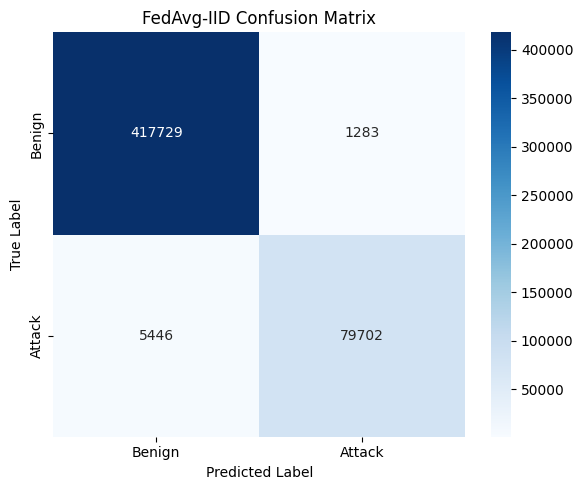

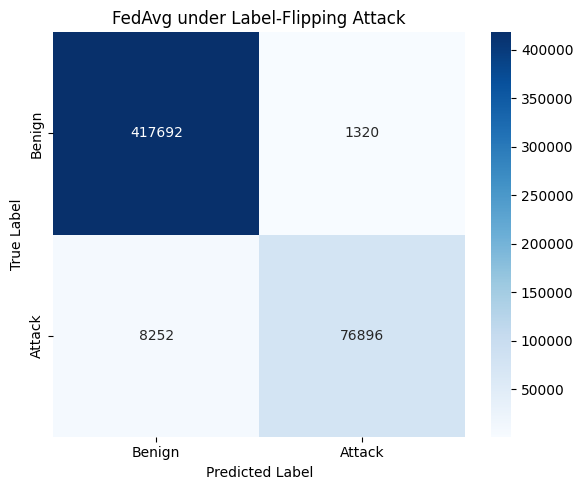

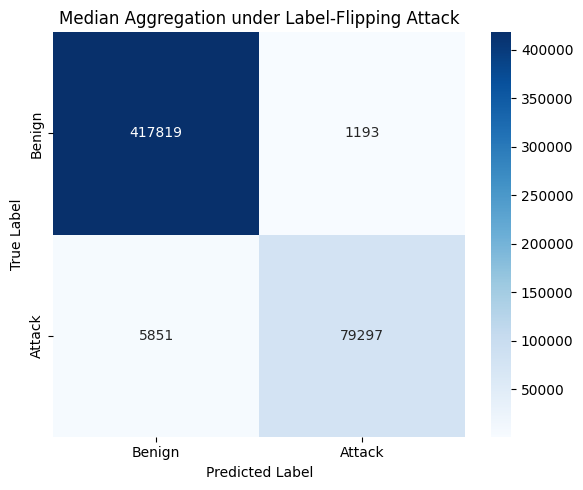

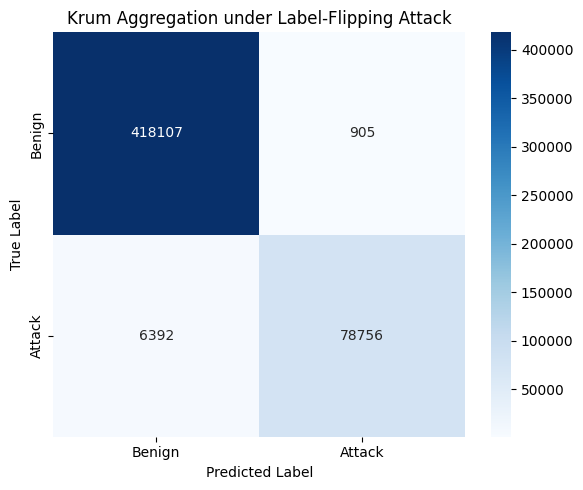

FedAvg-IID Confusion Matrix:
[[417729   1283]
 [  5446  79702]]

FedAvg-Poisoned Confusion Matrix:
[[417692   1320]
 [  8252  76896]]

Median-Poisoned Confusion Matrix:
[[417819   1193]
 [  5851  79297]]

Krum-Poisoned Confusion Matrix:
[[418107    905]
 [  6392  78756]]


In [21]:
# ============================================================
# 19. CONFUSION MATRICES
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


# ------------------------------------------------------------
# Create clean FedAvg-IID model from saved weights
# ------------------------------------------------------------

iid_final_model = create_model()
set_model_weights(iid_final_model, iid_global_weights)


# ------------------------------------------------------------
# Function to obtain predictions
# ------------------------------------------------------------

def get_model_predictions(model, X_test, y_test):
    
    probabilities = model.predict(
        X_test,
        batch_size=1024,
        verbose=0
    ).ravel()
    
    predictions = (
        probabilities >= 0.5
    ).astype(np.int8)
    
    cm = confusion_matrix(
        y_test,
        predictions
    )
    
    return predictions, probabilities, cm


# ------------------------------------------------------------
# Generate predictions
# ------------------------------------------------------------

iid_predictions, iid_probabilities, iid_cm = get_model_predictions(
    iid_final_model,
    X_test_scaled,
    y_test
)

poisoned_predictions, poisoned_probabilities, poisoned_cm = get_model_predictions(
    poisoned_global_model,
    X_test_scaled,
    y_test
)

median_predictions, median_probabilities, median_cm = get_model_predictions(
    median_global_model,
    X_test_scaled,
    y_test
)

krum_predictions, krum_probabilities, krum_cm = get_model_predictions(
    krum_global_model,
    X_test_scaled,
    y_test
)


print("Confusion matrices generated successfully.")


# FedAvg-IID Confusion Matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    iid_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("FedAvg-IID Confusion Matrix")

plt.tight_layout()
plt.show()


# FedAvg-Poisoned Confusion Matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    poisoned_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("FedAvg under Label-Flipping Attack")

plt.tight_layout()
plt.show()


# Median-Poisoned Confusion Matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    median_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Median Aggregation under Label-Flipping Attack")

plt.tight_layout()
plt.show()



# Krum-Poisoned Confusion Matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    krum_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Krum Aggregation under Label-Flipping Attack")

plt.tight_layout()
plt.show()




print("FedAvg-IID Confusion Matrix:")
print(iid_cm)

print("\nFedAvg-Poisoned Confusion Matrix:")
print(poisoned_cm)

print("\nMedian-Poisoned Confusion Matrix:")
print(median_cm)

print("\nKrum-Poisoned Confusion Matrix:")
print(krum_cm)

ROC curves generated successfully.
FedAvg-IID       AUC: 0.999306
FedAvg-Poisoned  AUC: 0.998562
Median-Poisoned  AUC: 0.999044
Krum-Poisoned    AUC: 0.999316


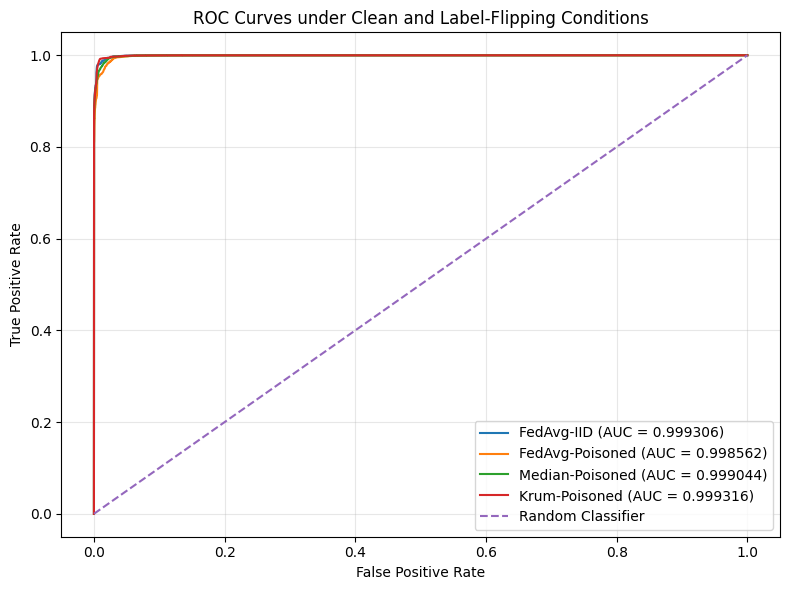

,Model,ROC-AUC
0,FedAvg-IID,0.999306
1,FedAvg-Poisoned,0.998562
2,Median-Poisoned,0.999044
3,Krum-Poisoned,0.999316


In [22]:
# ============================================================
# 20. ROC CURVES
# ============================================================

from sklearn.metrics import roc_curve, auc

# Generate ROC curve values
fpr_iid, tpr_iid, _ = roc_curve(
    y_test,
    iid_probabilities
)

fpr_poisoned, tpr_poisoned, _ = roc_curve(
    y_test,
    poisoned_probabilities
)

fpr_median, tpr_median, _ = roc_curve(
    y_test,
    median_probabilities
)

fpr_krum, tpr_krum, _ = roc_curve(
    y_test,
    krum_probabilities
)

# Calculate AUC values
auc_iid = auc(fpr_iid, tpr_iid)
auc_poisoned = auc(fpr_poisoned, tpr_poisoned)
auc_median = auc(fpr_median, tpr_median)
auc_krum = auc(fpr_krum, tpr_krum)

print("ROC curves generated successfully.")

print(f"FedAvg-IID       AUC: {auc_iid:.6f}")
print(f"FedAvg-Poisoned  AUC: {auc_poisoned:.6f}")
print(f"Median-Poisoned  AUC: {auc_median:.6f}")
print(f"Krum-Poisoned    AUC: {auc_krum:.6f}")


# ============================================================
# ROC CURVE COMPARISON
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_iid,
    tpr_iid,
    label=f"FedAvg-IID (AUC = {auc_iid:.6f})"
)

plt.plot(
    fpr_poisoned,
    tpr_poisoned,
    label=f"FedAvg-Poisoned (AUC = {auc_poisoned:.6f})"
)

plt.plot(
    fpr_median,
    tpr_median,
    label=f"Median-Poisoned (AUC = {auc_median:.6f})"
)

plt.plot(
    fpr_krum,
    tpr_krum,
    label=f"Krum-Poisoned (AUC = {auc_krum:.6f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves under Clean and Label-Flipping Conditions")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# ROC-AUC SUMMARY TABLE
# ============================================================

roc_results = pd.DataFrame({
    "Model": [
        "FedAvg-IID",
        "FedAvg-Poisoned",
        "Median-Poisoned",
        "Krum-Poisoned"
    ],
    "ROC-AUC": [
        auc_iid,
        auc_poisoned,
        auc_median,
        auc_krum
    ]
})

display(roc_results)

In [23]:
# ============================================================
# 21 — PERFORMANCE TABLES
# ============================================================

import pandas as pd
import numpy as np

print("=" * 60)
print("SECTION 21 — PERFORMANCE TABLES")
print("=" * 60)


# ------------------------------------------------------------
# 21.1 Overall Model Comparison
# ------------------------------------------------------------

overall_results = pd.DataFrame({
    "Model": [
        "FedAvg-IID",
        "FedAvg-Poisoned",
        "Median-Poisoned",
        "Krum-Poisoned"
    ],
    "Accuracy": [
        0.986653,
        0.981014,
        0.986028,
        0.985526
    ],
    "Precision": [
        0.984158,
        0.983124,
        0.985178,
        0.988639
    ],
    "Recall": [
        0.936041,
        0.903086,
        0.931284,
        0.924931
    ],
    "F1-Score": [
        0.959496,
        0.941407,
        0.957474,
        0.955725
    ],
    "ROC-AUC": [
        0.999306,
        0.998562,
        0.999044,
        0.999316
    ]
})

# Display rounded table
overall_results_rounded = overall_results.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

overall_results_rounded[metric_columns] = (
    overall_results_rounded[metric_columns].round(6)
)

print("\nOverall Model Comparison:")
display(overall_results_rounded)



# ------------------------------------------------------------
# 21.2 Improvement over Poisoned FedAvg
# ------------------------------------------------------------

poisoned_fedavg = overall_results[
    overall_results["Model"] == "FedAvg-Poisoned"
].iloc[0]

median_model = overall_results[
    overall_results["Model"] == "Median-Poisoned"
].iloc[0]

krum_model = overall_results[
    overall_results["Model"] == "Krum-Poisoned"
].iloc[0]

improvement_results = pd.DataFrame({
    "Method": [
        "FedAvg-Poisoned",
        "Median-Poisoned",
        "Krum-Poisoned"
    ],
    "Accuracy Δ": [
        0,
        median_model["Accuracy"] - poisoned_fedavg["Accuracy"],
        krum_model["Accuracy"] - poisoned_fedavg["Accuracy"]
    ],
    "Precision Δ": [
        0,
        median_model["Precision"] - poisoned_fedavg["Precision"],
        krum_model["Precision"] - poisoned_fedavg["Precision"]
    ],
    "Recall Δ": [
        0,
        median_model["Recall"] - poisoned_fedavg["Recall"],
        krum_model["Recall"] - poisoned_fedavg["Recall"]
    ],
    "F1-Score Δ": [
        0,
        median_model["F1-Score"] - poisoned_fedavg["F1-Score"],
        krum_model["F1-Score"] - poisoned_fedavg["F1-Score"]
    ],
    "ROC-AUC Δ": [
        0,
        median_model["ROC-AUC"] - poisoned_fedavg["ROC-AUC"],
        krum_model["ROC-AUC"] - poisoned_fedavg["ROC-AUC"]
    ]
})

improvement_results = improvement_results.round(6)

print("\nImprovement over Poisoned FedAvg:")
display(improvement_results)



# ------------------------------------------------------------
# 21.3 Clean vs. Poisoned Performance
# ------------------------------------------------------------

clean_vs_poisoned = overall_results[
    overall_results["Model"].isin([
        "FedAvg-IID",
        "FedAvg-Poisoned",
        "Median-Poisoned",
        "Krum-Poisoned"
    ])
].copy()

clean_vs_poisoned[metric_columns] = (
    clean_vs_poisoned[metric_columns].round(6)
)

print("\nClean vs. Poisoned Performance:")
display(clean_vs_poisoned)




# ------------------------------------------------------------
# 21.4 Performance Change Relative to Clean FedAvg
# ------------------------------------------------------------

clean_fedavg = overall_results[
    overall_results["Model"] == "FedAvg-IID"
].iloc[0]

comparison_rows = []

for _, row in overall_results.iterrows():

    comparison_rows.append({
        "Model": row["Model"],
        "Accuracy Δ": row["Accuracy"] - clean_fedavg["Accuracy"],
        "Precision Δ": row["Precision"] - clean_fedavg["Precision"],
        "Recall Δ": row["Recall"] - clean_fedavg["Recall"],
        "F1-Score Δ": row["F1-Score"] - clean_fedavg["F1-Score"],
        "ROC-AUC Δ": row["ROC-AUC"] - clean_fedavg["ROC-AUC"]
    })

clean_comparison = pd.DataFrame(comparison_rows)

clean_comparison = clean_comparison.round(6)

print("\nPerformance Change Relative to Clean FedAvg-IID:")
display(clean_comparison)


# ------------------------------------------------------------
# 21.5 Save Tables
# ------------------------------------------------------------

overall_results_rounded.to_csv(
    "table_overall_model_comparison.csv",
    index=False
)

improvement_results.to_csv(
    "table_improvement_over_poisoned_fedavg.csv",
    index=False
)

clean_vs_poisoned.to_csv(
    "table_clean_vs_poisoned.csv",
    index=False
)

clean_comparison.to_csv(
    "table_change_relative_to_clean_fedavg.csv",
    index=False
)

print("\nAll performance tables saved successfully.")


# ------------------------------------------------------------
# 21.6 Publication-Ready Main Table
# ------------------------------------------------------------

publication_table = overall_results.copy()

publication_table[metric_columns] = (
    publication_table[metric_columns] * 100
).round(2)

print("\nPublication-Ready Performance Table:")
display(publication_table)

SECTION 21 — PERFORMANCE TABLES

Overall Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,FedAvg-IID,0.986653,0.984158,0.936041,0.959496,0.999306
1,FedAvg-Poisoned,0.981014,0.983124,0.903086,0.941407,0.998562
2,Median-Poisoned,0.986028,0.985178,0.931284,0.957474,0.999044
3,Krum-Poisoned,0.985526,0.988639,0.924931,0.955725,0.999316



Improvement over Poisoned FedAvg:


,Method,Accuracy Δ,Precision Δ,Recall Δ,F1-Score Δ,ROC-AUC Δ
0,FedAvg-Poisoned,0.000000,0.000000,0.000000,0.000000,0.000000
1,Median-Poisoned,0.005014,0.002054,0.028198,0.016067,0.000482
2,Krum-Poisoned,0.004512,0.005515,0.021845,0.014318,0.000754



Clean vs. Poisoned Performance:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,FedAvg-IID,0.986653,0.984158,0.936041,0.959496,0.999306
1,FedAvg-Poisoned,0.981014,0.983124,0.903086,0.941407,0.998562
2,Median-Poisoned,0.986028,0.985178,0.931284,0.957474,0.999044
3,Krum-Poisoned,0.985526,0.988639,0.924931,0.955725,0.999316



Performance Change Relative to Clean FedAvg-IID:


,Model,Accuracy Δ,Precision Δ,Recall Δ,F1-Score Δ,ROC-AUC Δ
0,FedAvg-IID,0.000000,0.000000,0.000000,0.000000,0.000000
1,FedAvg-Poisoned,-0.005639,-0.001034,-0.032955,-0.018089,-0.000744
2,Median-Poisoned,-0.000625,0.001020,-0.004757,-0.002022,-0.000262
3,Krum-Poisoned,-0.001127,0.004481,-0.011110,-0.003771,0.000010



All performance tables saved successfully.

Publication-Ready Performance Table:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,FedAvg-IID,98.67,98.42,93.60,95.95,99.93
1,FedAvg-Poisoned,98.10,98.31,90.31,94.14,99.86
2,Median-Poisoned,98.60,98.52,93.13,95.75,99.90
3,Krum-Poisoned,98.55,98.86,92.49,95.57,99.93


SECTION 22 — TRAINING-ROUND GRAPHS

Checking required training histories:

fedavg_iid_history: Available
fedavg_noniid_history: Available
fedavg_poisoned_history: Available
median_history: Available
krum_history: Available

FedAvg-IID History:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Round
0,0.976722,0.936177,0.925248,0.930680,0.997035,1
1,0.982448,0.962873,0.932012,0.947191,0.998450,2
2,0.984360,0.969074,0.937309,0.952927,0.998715,3
3,0.983888,0.963074,0.940668,0.951739,0.998746,4
4,0.985064,0.966085,0.944732,0.955289,0.998907,5
5,0.985239,0.979430,0.932177,0.955219,0.998909,6
6,0.987117,0.972714,0.950381,0.961418,0.998950,7
7,0.987079,0.984952,0.937826,0.960811,0.999118,8
8,0.986504,0.983259,0.936029,0.959063,0.999171,9
9,0.986653,0.984158,0.936041,0.959496,0.999306,10



FedAvg-NonIID History:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Round
0,0.980881,0.989968,0.895875,0.940574,0.998179,1
1,0.983918,0.975955,0.927632,0.951180,0.998543,2
2,0.985138,0.983946,0.927127,0.954692,0.998721,3
3,0.988494,0.985119,0.946164,0.965249,0.999024,4
4,0.988940,0.981030,0.952941,0.966781,0.999125,5
5,0.993308,0.991809,0.968373,0.979951,0.999512,6
6,0.987919,0.989547,0.938378,0.963284,0.999196,7
7,0.984295,0.982398,0.923557,0.952069,0.998688,8
8,0.984642,0.983485,0.924590,0.953129,0.998740,9
9,0.984820,0.966472,0.942829,0.954504,0.998818,10



FedAvg-Poisoned History:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Round
0,0.976057,0.926637,0.932024,0.929323,0.997093,1
1,0.976736,0.957559,0.902241,0.929077,0.996889,2
2,0.977410,0.952193,0.912036,0.931682,0.996881,3
3,0.980619,0.974409,0.909123,0.940635,0.996915,4
4,0.979826,0.974352,0.904355,0.938049,0.997365,5
5,0.980506,0.978174,0.904766,0.940039,0.998137,6
6,0.981797,0.978064,0.912693,0.944248,0.998417,7
7,0.985382,0.953993,0.959729,0.956852,0.998659,8
8,0.985751,0.958536,0.957028,0.957781,0.998749,9
9,0.981014,0.983124,0.903086,0.941407,0.998562,10



Median-Poisoned History:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Round
0,0.978471,0.959217,0.911272,0.934630,0.997376,1
1,0.981367,0.960455,0.927879,0.943886,0.998349,2
2,0.983454,0.967816,0.933058,0.950119,0.998690,3
3,0.984457,0.971403,0.935512,0.953120,0.998838,4
4,0.985100,0.981852,0.928947,0.954667,0.998859,5
5,0.985340,0.980723,0.931507,0.955482,0.998931,6
6,0.987675,0.981317,0.945013,0.962823,0.999056,7
7,0.983612,0.981019,0.920785,0.949948,0.998737,8
8,0.985804,0.986829,0.928337,0.956690,0.999045,9
9,0.986028,0.985178,0.931284,0.957474,0.999044,10



Krum-Poisoned History:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Round
0,0.979687,0.948185,0.930580,0.939300,0.997457,1
1,0.980929,0.950916,0.935360,0.943074,0.998083,2
2,0.981615,0.977689,0.911953,0.943678,0.998450,3
3,0.984763,0.945340,0.965613,0.955369,0.998665,4
4,0.984475,0.974869,0.932106,0.953008,0.998802,5
5,0.984166,0.982191,0.922981,0.951666,0.998805,6
6,0.985346,0.985212,0.927150,0.955300,0.998994,7
7,0.984973,0.988243,0.921995,0.953970,0.999156,8
8,0.986455,0.952444,0.968138,0.960227,0.998901,9
9,0.985526,0.988639,0.924931,0.955725,0.999316,10


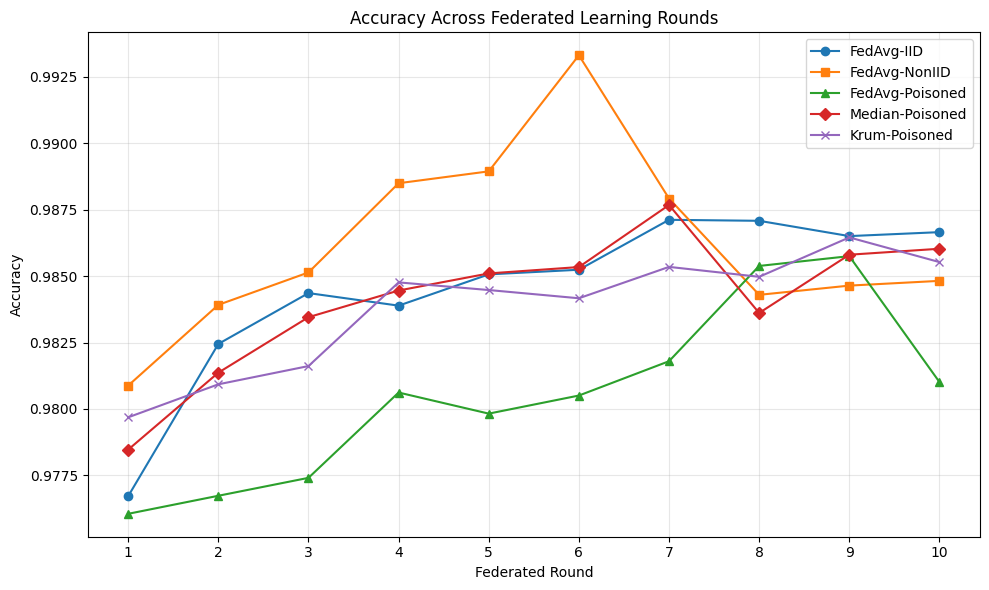

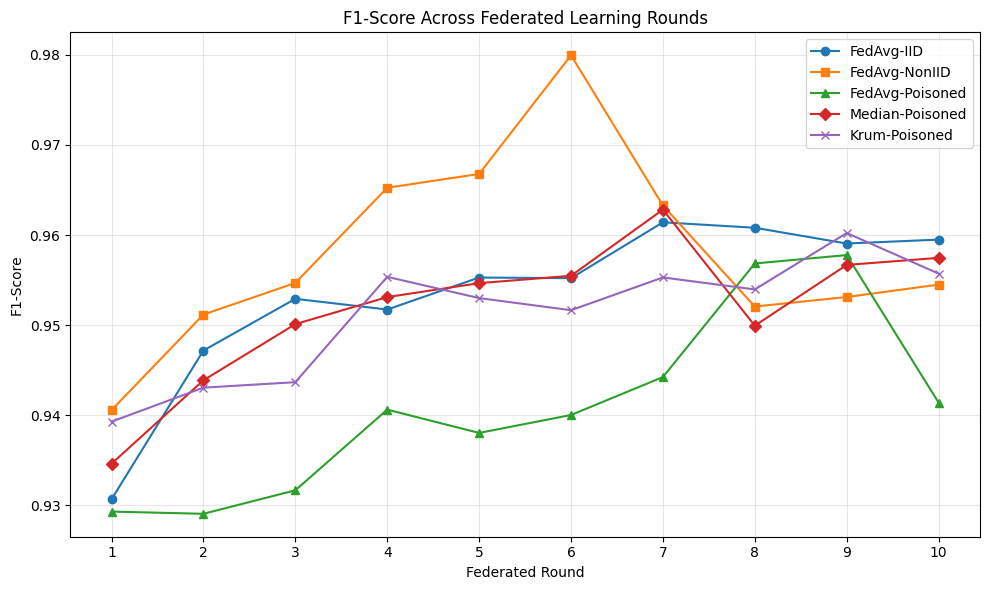

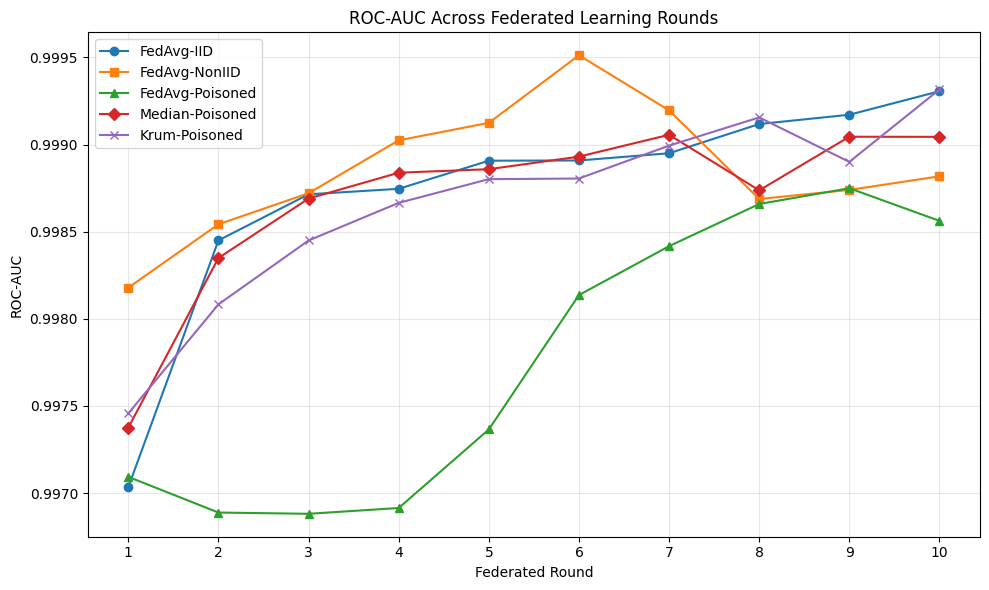


Combined Round-Wise Results:


,Round,FedAvg-IID Accuracy,FedAvg-IID F1,FedAvg-NonIID Accuracy,FedAvg-NonIID F1,FedAvg-Poisoned Accuracy,FedAvg-Poisoned F1,Median-Poisoned Accuracy,Median-Poisoned F1,Krum-Poisoned Accuracy,Krum-Poisoned F1
0,1,0.976722,0.930680,0.980881,0.940574,0.976057,0.929323,0.978471,0.934630,0.979687,0.939300
1,2,0.982448,0.947191,0.983918,0.951180,0.976736,0.929077,0.981367,0.943886,0.980929,0.943074
2,3,0.984360,0.952927,0.985138,0.954692,0.977410,0.931682,0.983454,0.950119,0.981615,0.943678
3,4,0.983888,0.951739,0.988494,0.965249,0.980619,0.940635,0.984457,0.953120,0.984763,0.955369
4,5,0.985064,0.955289,0.988940,0.966781,0.979826,0.938049,0.985100,0.954667,0.984475,0.953008
5,6,0.985239,0.955219,0.993308,0.979951,0.980506,0.940039,0.985340,0.955482,0.984166,0.951666
6,7,0.987117,0.961418,0.987919,0.963284,0.981797,0.944248,0.987675,0.962823,0.985346,0.955300
7,8,0.987079,0.960811,0.984295,0.952069,0.985382,0.956852,0.983612,0.949948,0.984973,0.953970
8,9,0.986504,0.959063,0.984642,0.953129,0.985751,0.957781,0.985804,0.956690,0.986455,0.960227
9,10,0.986653,0.959496,0.984820,0.954504,0.981014,0.941407,0.986028,0.957474,0.985526,0.955725



Round-wise results saved successfully.

Saved Section 22 Figures:

✓ figure_accuracy_vs_round.png
✓ figure_f1_vs_round.png
✓ figure_roc_auc_vs_round.png

SECTION 22 COMPLETED SUCCESSFULLY


In [26]:
# ============================================================
# 22 — TRAINING-ROUND GRAPHS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

print("=" * 60)
print("SECTION 22 — TRAINING-ROUND GRAPHS")
print("=" * 60)


# ------------------------------------------------------------
# 22.1 Check Required Histories
# ------------------------------------------------------------

required_histories = [
    "fedavg_iid_history",
    "fedavg_noniid_history",
    "fedavg_poisoned_history",
    "median_history",
    "krum_history"
]

print("\nChecking required training histories:\n")

for history_name in required_histories:
    print(
        f"{history_name}:",
        "Available" if history_name in globals() else "NOT FOUND"
    )


# ------------------------------------------------------------
# 22.2 Convert Training Histories to DataFrames
# ------------------------------------------------------------

fedavg_iid_history_df = pd.DataFrame(fedavg_iid_history)

fedavg_noniid_history_df = pd.DataFrame(fedavg_noniid_history)

fedavg_poisoned_history_df = pd.DataFrame(
    fedavg_poisoned_history
)

median_history_df = pd.DataFrame(median_history)

krum_history_df = pd.DataFrame(krum_history)


print("\nFedAvg-IID History:")
display(fedavg_iid_history_df)

print("\nFedAvg-NonIID History:")
display(fedavg_noniid_history_df)

print("\nFedAvg-Poisoned History:")
display(fedavg_poisoned_history_df)

print("\nMedian-Poisoned History:")
display(median_history_df)

print("\nKrum-Poisoned History:")
display(krum_history_df)


# ------------------------------------------------------------
# 22.3 Accuracy vs Federated Round
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    fedavg_iid_history_df["Round"],
    fedavg_iid_history_df["Accuracy"],
    marker="o",
    label="FedAvg-IID"
)

plt.plot(
    fedavg_noniid_history_df["Round"],
    fedavg_noniid_history_df["Accuracy"],
    marker="s",
    label="FedAvg-NonIID"
)

plt.plot(
    fedavg_poisoned_history_df["Round"],
    fedavg_poisoned_history_df["Accuracy"],
    marker="^",
    label="FedAvg-Poisoned"
)

plt.plot(
    median_history_df["Round"],
    median_history_df["Accuracy"],
    marker="D",
    label="Median-Poisoned"
)

plt.plot(
    krum_history_df["Round"],
    krum_history_df["Accuracy"],
    marker="x",
    label="Krum-Poisoned"
)

plt.xlabel("Federated Round")
plt.ylabel("Accuracy")
plt.title("Accuracy Across Federated Learning Rounds")

plt.xticks(range(1, 11))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "figure_accuracy_vs_round.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 22.4 F1-Score vs Federated Round
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    fedavg_iid_history_df["Round"],
    fedavg_iid_history_df["F1-Score"],
    marker="o",
    label="FedAvg-IID"
)

plt.plot(
    fedavg_noniid_history_df["Round"],
    fedavg_noniid_history_df["F1-Score"],
    marker="s",
    label="FedAvg-NonIID"
)

plt.plot(
    fedavg_poisoned_history_df["Round"],
    fedavg_poisoned_history_df["F1-Score"],
    marker="^",
    label="FedAvg-Poisoned"
)

plt.plot(
    median_history_df["Round"],
    median_history_df["F1-Score"],
    marker="D",
    label="Median-Poisoned"
)

plt.plot(
    krum_history_df["Round"],
    krum_history_df["F1-Score"],
    marker="x",
    label="Krum-Poisoned"
)

plt.xlabel("Federated Round")
plt.ylabel("F1-Score")
plt.title("F1-Score Across Federated Learning Rounds")

plt.xticks(range(1, 11))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "figure_f1_vs_round.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 22.5 ROC-AUC vs Federated Round
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    fedavg_iid_history_df["Round"],
    fedavg_iid_history_df["ROC-AUC"],
    marker="o",
    label="FedAvg-IID"
)

plt.plot(
    fedavg_noniid_history_df["Round"],
    fedavg_noniid_history_df["ROC-AUC"],
    marker="s",
    label="FedAvg-NonIID"
)

plt.plot(
    fedavg_poisoned_history_df["Round"],
    fedavg_poisoned_history_df["ROC-AUC"],
    marker="^",
    label="FedAvg-Poisoned"
)

plt.plot(
    median_history_df["Round"],
    median_history_df["ROC-AUC"],
    marker="D",
    label="Median-Poisoned"
)

plt.plot(
    krum_history_df["Round"],
    krum_history_df["ROC-AUC"],
    marker="x",
    label="Krum-Poisoned"
)

plt.xlabel("Federated Round")
plt.ylabel("ROC-AUC")
plt.title("ROC-AUC Across Federated Learning Rounds")

plt.xticks(range(1, 11))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "figure_roc_auc_vs_round.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 22.6 Combined Round-Wise Results
# ------------------------------------------------------------

roundwise_results = pd.DataFrame({
    "Round": fedavg_iid_history_df["Round"],

    "FedAvg-IID Accuracy":
        fedavg_iid_history_df["Accuracy"],

    "FedAvg-IID F1":
        fedavg_iid_history_df["F1-Score"],

    "FedAvg-NonIID Accuracy":
        fedavg_noniid_history_df["Accuracy"],

    "FedAvg-NonIID F1":
        fedavg_noniid_history_df["F1-Score"],

    "FedAvg-Poisoned Accuracy":
        fedavg_poisoned_history_df["Accuracy"],

    "FedAvg-Poisoned F1":
        fedavg_poisoned_history_df["F1-Score"],

    "Median-Poisoned Accuracy":
        median_history_df["Accuracy"],

    "Median-Poisoned F1":
        median_history_df["F1-Score"],

    "Krum-Poisoned Accuracy":
        krum_history_df["Accuracy"],

    "Krum-Poisoned F1":
        krum_history_df["F1-Score"]
})

roundwise_results = roundwise_results.round(6)

print("\nCombined Round-Wise Results:")
display(roundwise_results)


# ------------------------------------------------------------
# 22.7 Save Round-Wise Results
# ------------------------------------------------------------

roundwise_results.to_csv(
    "table_roundwise_training_results.csv",
    index=False
)

print("\nRound-wise results saved successfully.")


# ------------------------------------------------------------
# 22.8 Confirm Saved Figures
# ------------------------------------------------------------

figure_files = [
    "figure_accuracy_vs_round.png",
    "figure_f1_vs_round.png",
    "figure_roc_auc_vs_round.png"
]

print("\nSaved Section 22 Figures:\n")

for filename in figure_files:

    if os.path.exists(filename):
        print(f"✓ {filename}")

    else:
        print(f"✗ {filename} NOT FOUND")


print("\n" + "=" * 60)
print("SECTION 22 COMPLETED SUCCESSFULLY")
print("=" * 60)

SECTION 23 — FINAL COMPARISON

Final Round Performance:


,Method,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,FedAvg-IID,0.986653,0.984158,0.936041,0.959496,0.999306
1,FedAvg-NonIID,0.984820,0.966472,0.942829,0.954504,0.998818
2,FedAvg-Poisoned,0.981014,0.983124,0.903086,0.941407,0.998562
3,Median-Poisoned,0.986028,0.985178,0.931284,0.957474,0.999044
4,Krum-Poisoned,0.985526,0.988639,0.924931,0.955725,0.999316



Publication-Ready Final Comparison (%):


,Method,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,FedAvg-IID,98.67%,98.42%,93.60%,95.95%,99.93%
1,FedAvg-NonIID,98.48%,96.65%,94.28%,95.45%,99.88%
2,FedAvg-Poisoned,98.10%,98.31%,90.31%,94.14%,99.86%
3,Median-Poisoned,98.60%,98.52%,93.13%,95.75%,99.90%
4,Krum-Poisoned,98.55%,98.86%,92.49%,95.57%,99.93%



Improvement over FedAvg under Label-Flipping Attack:


,Metric,Median Improvement,Krum Improvement
0,Accuracy,+0.005014,+0.004512
1,Precision,+0.002055,+0.005516
2,Recall,+0.028198,+0.021844
3,F1-Score,+0.016067,+0.014318
4,ROC-AUC,+0.000482,+0.000754



Best Performing Method for Each Metric:
Accuracy    : FedAvg-IID           (0.986653)
Precision   : Krum-Poisoned        (0.988639)
Recall      : FedAvg-NonIID        (0.942829)
F1-Score    : FedAvg-IID           (0.959496)
ROC-AUC     : Krum-Poisoned        (0.999316)


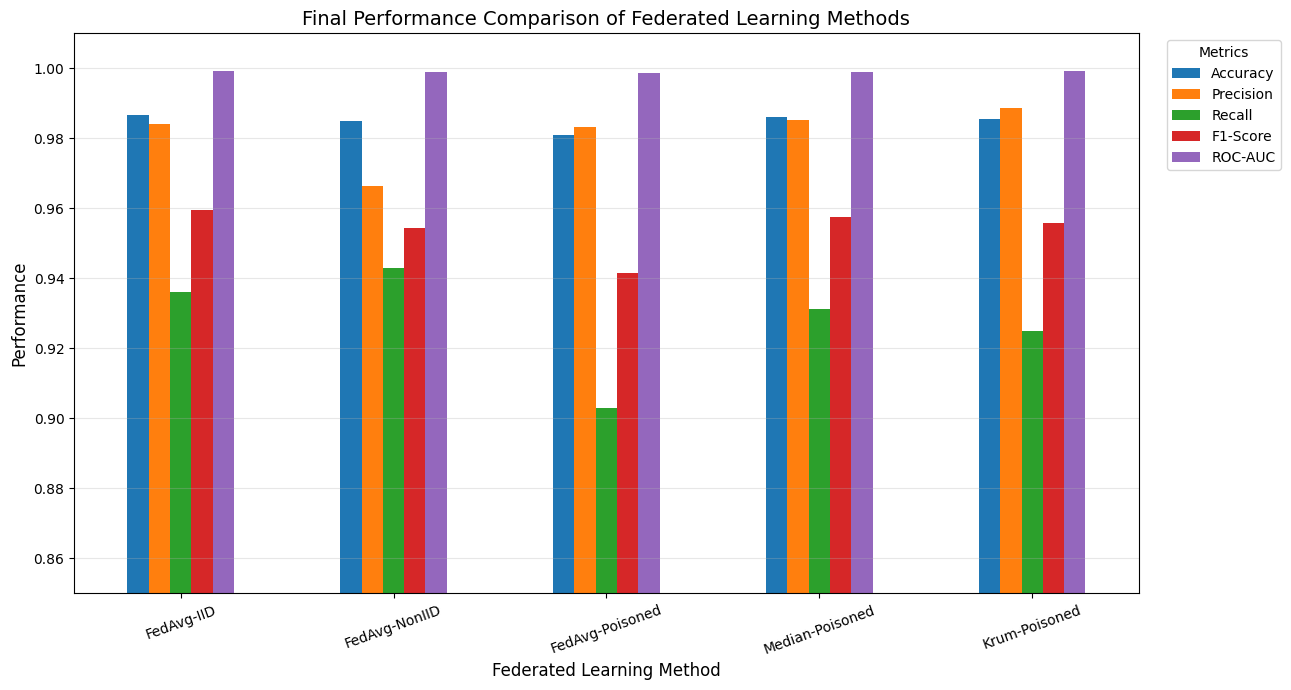

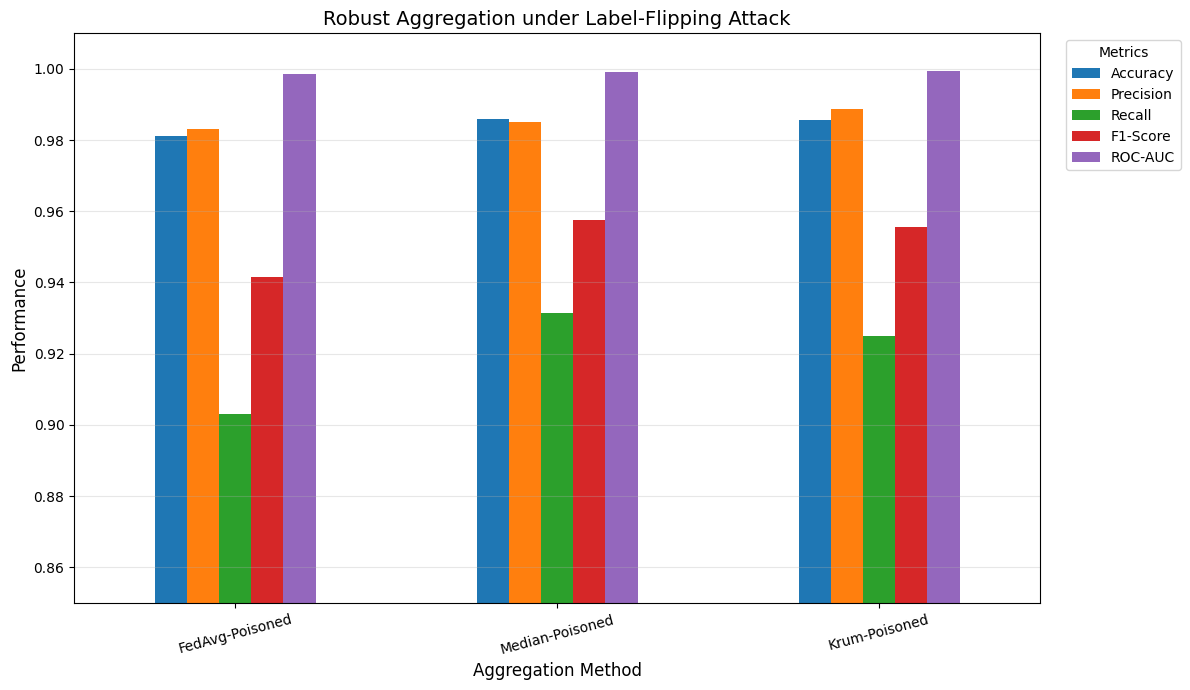


Saved Section 23 files:
✓ table_final_comparison_decimal.csv
✓ table_final_comparison_percentage.csv
✓ table_robustness_improvement.csv
✓ figure_final_performance_comparison.png
✓ figure_robust_aggregation_comparison.png

SECTION 23 COMPLETED SUCCESSFULLY


In [27]:
# ============================================================
# 23 — FINAL COMPARISON
# ============================================================

print("=" * 60)
print("SECTION 23 — FINAL COMPARISON")
print("=" * 60)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. FINAL ROUND RESULTS
# ------------------------------------------------------------

final_results = pd.DataFrame({
    "Method": [
        "FedAvg-IID",
        "FedAvg-NonIID",
        "FedAvg-Poisoned",
        "Median-Poisoned",
        "Krum-Poisoned"
    ],
    "Accuracy": [
        fedavg_iid_history[-1]["Accuracy"],
        fedavg_noniid_history[-1]["Accuracy"],
        fedavg_poisoned_history[-1]["Accuracy"],
        median_history[-1]["Accuracy"],
        krum_history[-1]["Accuracy"]
    ],
    "Precision": [
        fedavg_iid_history[-1]["Precision"],
        fedavg_noniid_history[-1]["Precision"],
        fedavg_poisoned_history[-1]["Precision"],
        median_history[-1]["Precision"],
        krum_history[-1]["Precision"]
    ],
    "Recall": [
        fedavg_iid_history[-1]["Recall"],
        fedavg_noniid_history[-1]["Recall"],
        fedavg_poisoned_history[-1]["Recall"],
        median_history[-1]["Recall"],
        krum_history[-1]["Recall"]
    ],
    "F1-Score": [
        fedavg_iid_history[-1]["F1-Score"],
        fedavg_noniid_history[-1]["F1-Score"],
        fedavg_poisoned_history[-1]["F1-Score"],
        median_history[-1]["F1-Score"],
        krum_history[-1]["F1-Score"]
    ],
    "ROC-AUC": [
        fedavg_iid_history[-1]["ROC-AUC"],
        fedavg_noniid_history[-1]["ROC-AUC"],
        fedavg_poisoned_history[-1]["ROC-AUC"],
        median_history[-1]["ROC-AUC"],
        krum_history[-1]["ROC-AUC"]
    ]
})

print("\nFinal Round Performance:")
display(
    final_results.style.format({
        "Accuracy": "{:.6f}",
        "Precision": "{:.6f}",
        "Recall": "{:.6f}",
        "F1-Score": "{:.6f}",
        "ROC-AUC": "{:.6f}"
    })
)

# ------------------------------------------------------------
# 2. CONVERT TO PERCENTAGE FOR PAPER
# ------------------------------------------------------------

final_results_percentage = final_results.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

for col in metric_columns:
    final_results_percentage[col] *= 100

print("\nPublication-Ready Final Comparison (%):")

display(
    final_results_percentage.style.format({
        "Accuracy": "{:.2f}%",
        "Precision": "{:.2f}%",
        "Recall": "{:.2f}%",
        "F1-Score": "{:.2f}%",
        "ROC-AUC": "{:.2f}%"
    })
)

# ------------------------------------------------------------
# 3. ROBUSTNESS IMPROVEMENT OVER POISONED FEDAVG
# ------------------------------------------------------------

poisoned = final_results[
    final_results["Method"] == "FedAvg-Poisoned"
].iloc[0]

median_result = final_results[
    final_results["Method"] == "Median-Poisoned"
].iloc[0]

krum_result = final_results[
    final_results["Method"] == "Krum-Poisoned"
].iloc[0]

robustness_comparison = pd.DataFrame({
    "Metric": metric_columns,

    "Median Improvement": [
        median_result[m] - poisoned[m]
        for m in metric_columns
    ],

    "Krum Improvement": [
        krum_result[m] - poisoned[m]
        for m in metric_columns
    ]
})

print("\nImprovement over FedAvg under Label-Flipping Attack:")

display(
    robustness_comparison.style.format({
        "Median Improvement": "{:+.6f}",
        "Krum Improvement": "{:+.6f}"
    })
)

# ------------------------------------------------------------
# 4. BEST METHOD FOR EACH METRIC
# ------------------------------------------------------------

print("\nBest Performing Method for Each Metric:")

for metric in metric_columns:
    best_index = final_results[metric].idxmax()
    best_method = final_results.loc[best_index, "Method"]
    best_value = final_results.loc[best_index, metric]

    print(
        f"{metric:12s}: "
        f"{best_method:20s} "
        f"({best_value:.6f})"
    )

# ------------------------------------------------------------
# 5. FINAL COMPARISON BAR GRAPH
# ------------------------------------------------------------

plot_data = final_results.set_index("Method")[metric_columns]

ax = plot_data.plot(
    kind="bar",
    figsize=(13, 7)
)

plt.title(
    "Final Performance Comparison of Federated Learning Methods",
    fontsize=14
)
plt.xlabel("Federated Learning Method", fontsize=12)
plt.ylabel("Performance", fontsize=12)

plt.xticks(rotation=20)
plt.ylim(0.85, 1.01)

plt.legend(
    title="Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figure_final_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 6. ROBUST AGGREGATION COMPARISON
# ------------------------------------------------------------

robust_methods = final_results[
    final_results["Method"].isin([
        "FedAvg-Poisoned",
        "Median-Poisoned",
        "Krum-Poisoned"
    ])
].copy()

robust_plot = robust_methods.set_index("Method")[metric_columns]

ax = robust_plot.plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title(
    "Robust Aggregation under Label-Flipping Attack",
    fontsize=14
)
plt.xlabel("Aggregation Method", fontsize=12)
plt.ylabel("Performance", fontsize=12)

plt.xticks(rotation=15)
plt.ylim(0.85, 1.01)

plt.legend(
    title="Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figure_robust_aggregation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 7. SAVE FINAL TABLES
# ------------------------------------------------------------

final_results.to_csv(
    "table_final_comparison_decimal.csv",
    index=False
)

final_results_percentage.to_csv(
    "table_final_comparison_percentage.csv",
    index=False
)

robustness_comparison.to_csv(
    "table_robustness_improvement.csv",
    index=False
)

print("\nSaved Section 23 files:")

print("✓ table_final_comparison_decimal.csv")
print("✓ table_final_comparison_percentage.csv")
print("✓ table_robustness_improvement.csv")
print("✓ figure_final_performance_comparison.png")
print("✓ figure_robust_aggregation_comparison.png")

print("\n" + "=" * 60)
print("SECTION 23 COMPLETED SUCCESSFULLY")
print("=" * 60)